# Bước 1. Đo hiện trạng của shop (Current Actual)

Bước này trả lời câu hỏi: **hiện nay mỗi shop bán được bao nhiêu contract mỗi tháng, và con số đó được tạo ra như thế nào.**

Một shop có hai cách tạo ra contract:
- **Bán trực tiếp:** khách đến shop, nhân viên bán hàng (SA) làm hồ sơ vay, hồ sơ được duyệt thì khách ký contract ngay tại shop.
- **Cross-sell (bán chéo):** shop tạo ra một lead (cơ hội mời khách đã có contract vay thêm), sau đó khách ký contract ở nơi khác, thường là kênh online.

Phần bán trực tiếp tách được thành ba con số nhân với nhau. Một hồ sơ không thành contract vì một trong hai lý do: công ty từ chối, hoặc hồ sơ bị hủy (khách đổi ý, thiếu giấy tờ), nên tỷ lệ ký được tách tiếp thành hai phần:

```
contract bán trực tiếp  =  số SA  ×  số hồ sơ mỗi SA  ×  tỷ lệ ký
tỷ lệ ký                =  1  −  tỷ lệ bị từ chối  −  tỷ lệ hủy
Current Actual của shop =  contract bán trực tiếp  +  contract cross-sell
```

Ví dụ với số tự đặt: một shop có 2 SA, mỗi SA làm 5 hồ sơ mỗi tháng, 20% hồ sơ bị từ chối và 10% bị hủy, tức 70% hồ sơ thành contract, thì shop bán trực tiếp 2 × 5 × 0,7 = 7 contract mỗi tháng. Nếu shop có thêm 1 contract cross-sell thì Current Actual là 8 contract mỗi tháng. Mục 1.7 kiểm tra công thức này trên một shop thật.

**Notebook đi theo đúng công thức trên:**
- 1.1. Chọn cách xếp hồ sơ và contract vào từng tháng.
- 1.2. Chọn danh sách shop được tính.
- 1.3. Bán trực tiếp: lần lượt số SA, số hồ sơ mỗi SA, tỷ lệ bị từ chối và tỷ lệ hủy. Sau đó xem các contract này mang lại bao nhiêu tiền, khách mua nhóm hàng gì, có mua bảo hiểm không, và có trả nợ đúng hạn không.
- 1.4. Lead của shop: shop có bao nhiêu lead, chốt được bao nhiêu, vì sao lead thất bại.
- 1.5. Cross-sell: nối lead với contract để biết contract nào ký ở nơi khác nhưng do lead của shop tạo ra.
- 1.6. Ghép tất cả thành một bảng, mỗi dòng là một shop trong một tháng.
- 1.7. Tính Current Actual của từng shop.
- 1.8. Ghi file kết quả. 1.9. Tạo hai bảng đầu vào cho Bước 2. 1.10. Tóm tắt.

**File kết quả** (thư mục `output/`):
- `shop_month.csv`: mỗi dòng là một shop trong một tháng, đủ các KPI (chỉ số đo hiệu quả). Bước 2 dùng bảng này để xem xu hướng của từng shop.
- `shop_current.csv`: mỗi dòng là một shop, gồm đặc điểm của shop, Current Actual và các KPI của quý 3/2026. Bước 2, 3 và 4 dùng bảng này.
- `shop_goods_mix.csv` và `shop_lead_result.csv`: cơ cấu nhóm hàng và kết quả lead của từng shop, dùng khi tìm nguyên nhân ở Bước 5.
- `lead_contract_match.csv`: danh sách contract được ghi công cho lead, để kiểm tra lại cách nối ở mục 1.5.

**Cách chạy:** giống Bước 0. Notebook cần `clean_data/` và `r3_db.py` nằm cùng thư mục, không cần chạy Bước 0 trước.

Ô dưới đây mở dữ liệu sạch, tạo hàm `q()` để chạy một câu SQL, và đặt ba tham số dùng chung cho cả notebook:
- `WINDOW_DAYS`: số ngày tối đa từ lúc giao lead tới lúc khách nộp hồ sơ, giải thích ở mục 1.5;
- `CA_FROM`, `CA_TO`: ba tháng dùng để tính Current Actual, giải thích ở mục 1.7;
- `LAST_MONTH`: tháng cuối cùng có đủ dữ liệu (09/2026);
- `RISK_FROM`, `RISK_TO`: tháng ký của các contract dùng để đo rủi ro, giải thích ở phần rủi ro của mục 1.3.

Ô này cũng đặt kiểu biểu đồ dùng chung: nền trắng, không có lưới, chữ trên biểu đồ bằng tiếng Anh. Hàm `luu_hinh()` lưu mỗi biểu đồ thành ảnh PNG trong thư mục `Bước 1/hinh/`.


In [1]:
import sys
from pathlib import Path
ROOT = next(q for q in [Path.cwd(), *Path.cwd().parents] if (q / 'Bước 1').exists())   # thư mục gốc của bài
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from r3_db import connect, save_csv

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100); 
def _fmt(x):
    if x != x: return 'NaN'
    if x == int(x): return f'{x:,.0f}'
    return f'{x:,.1f}' if abs(x) >= 100 else f'{x:,.3f}'
pd.set_option('display.float_format', _fmt)

con = connect()
def q(sql):
    return con.execute(sql).df()

# Kiểu biểu đồ dùng chung: nền trắng, không có lưới, chữ trên biểu đồ bằng tiếng Anh.
BLUE, ORANGE, GREEN, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
                     'axes.edgecolor': '#bdbcb8', 'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
                     'lines.linewidth': 2})

# Mỗi biểu đồ được lưu thành ảnh PNG trong thư mục Bước 1/hinh.
HINH = ROOT / 'Bước 1' / 'hinh'
HINH.mkdir(exist_ok=True)
def luu_hinh(fig, ten):
    fig.savefig(HINH / f'{ten}.png', dpi=200, bbox_inches='tight')

def phan_tram(so_le=0):
    # Định dạng trục theo phần trăm
    return plt.FuncFormatter(lambda v, _: f'{v:.{so_le}%}')

def ghi_so(ax, thanh, dinh_dang='{:,.0f}', **kw):
    # Ghi giá trị ở đầu mỗi thanh, thay cho lưới
    ax.bar_label(thanh, labels=[dinh_dang.format(v) for v in thanh.datavalues], padding=3, color=INK, fontsize=9, **kw)

def bo_truc_x(ax):
    # Bỏ trục hoành khi giá trị đã ghi trên từng thanh
    ax.set_xticks([]); ax.spines['bottom'].set_visible(False)

def bo_truc_y(ax):
    ax.set_yticks([]); ax.spines['left'].set_visible(False)

def ve_khoang(ax, nhan, giua, thap, cao, dinh_dang='{:.0%}', mau=BLUE):
    # Trung vị là chấm tròn, đoạn ngang chạy từ mức 25% đến mức 75% của các shop trong nhóm
    y = np.arange(len(nhan))[::-1]
    ax.hlines(y, thap, cao, color=mau, lw=6, alpha=0.3)
    ax.plot(giua, y, 'o', color=mau)
    for yi, g in zip(y, giua):
        ax.text(g, yi + 0.22, dinh_dang.format(g), ha='center', va='bottom', color=INK, fontsize=9)
    ax.set_yticks(y); ax.set_yticklabels(nhan); ax.set_ylim(-0.6, len(nhan) - 0.2)

WINDOW_DAYS = 30
CA_FROM, CA_TO = '2026-07-01', '2026-09-01'
LAST_MONTH = '2026-09-01'
RISK_FROM, RISK_TO = '2025-03-01', '2026-05-01'   # tháng ký của các contract dùng để đo rủi ro (Bước 0, mục 0.5)

def ve_cot_ngang(nhan, gia_tri, tieu_de, dinh_dang='{:.0%}', mau=BLUE, ten=None):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(nhan) + 1))
    ax.barh(nhan[::-1], gia_tri[::-1], color=mau)
    for i, v in enumerate(gia_tri[::-1]):
        ax.text(v, i, ' ' + dinh_dang.format(v), va='center', color=INK)
    ax.set_title(tieu_de, loc='left', color=INK)
    ax.set_xlim(0, max(gia_tri) * 1.18); bo_truc_x(ax)
    plt.tight_layout()
    if ten: luu_hinh(fig, ten)
    plt.show()

## 1.1. Xếp hồ sơ và contract vào tháng nào

Mỗi contract có hai ngày: ngày nộp hồ sơ và ngày ký. Số hồ sơ và số SA luôn đếm theo tháng nộp, vì đó là lúc SA làm việc. Còn contract thì có thể đếm theo tháng ký hoặc tháng nộp. Ví dụ một shop trong tháng 7 có 3 hồ sơ: A nộp và ký ngày 10/7, B nộp 31/7 nhưng ký 1/8, C bị từ chối.
- **Đếm contract theo tháng ký:** tháng 7 có 3 hồ sơ và 1 contract (tỷ lệ ký 33%), tháng 8 có 1 contract nhưng 0 hồ sơ, 0 SA. Công thức ở đầu notebook không tính được cho tháng 8.
- **Đếm contract theo tháng nộp:** tháng 7 có 3 hồ sơ và 2 contract (tỷ lệ ký 67%). Hồ sơ, SA và contract luôn cùng tháng. Cái giá là contract B bị tính về tháng 7 dù ký ngày 1/8.

Cái giá này chỉ đáng kể nếu nhiều contract như B. Câu lệnh dưới đây đếm, trong các contract đã ký (`is_signed` bằng 1, tức trạng thái Active, Finished, Paid off, Written off hoặc Signed), bao nhiêu contract ký cùng tháng nộp hồ sơ.

In [2]:
q('''select count(*) so_hd_da_ky, sum((sign_month=apply_month)::int) ky_cung_thang, ky_cung_thang/so_hd_da_ky ty_le
from contract where is_signed=1''')

,so_hd_da_ky,ky_cung_thang,ty_le
0,2715985,"2,705,218",0.996


Câu lệnh dưới đây đếm, nếu đếm contract theo tháng ký, có bao nhiêu shop-tháng (một shop trong một tháng) rơi vào trường hợp như tháng 8 ở ví dụ: có contract nhưng không có hồ sơ nào.

In [3]:
q(f'''with a as (select skp_salesroom, apply_month thang, count(*) ho_so from contract
   where skp_salesroom in (select skp_salesroom from salesroom) and apply_month<='{LAST_MONTH}' group by all),
k as (select skp_salesroom, sign_month thang, count(*) hd from contract
   where is_signed=1 and skp_salesroom in (select skp_salesroom from salesroom) and sign_month<='{LAST_MONTH}' group by all)
select count(*) shop_thang_co_hd_theo_thang_ky, count(*) filter (where a.ho_so is null) khong_co_ho_so_trong_thang,
  sum(k.hd) filter (where a.ho_so is null) so_hd_cua_cac_thang_nay
from k left join a using(skp_salesroom, thang)''')

,shop_thang_co_hd_theo_thang_ky,khong_co_ho_so_trong_thang,so_hd_cua_cac_thang_nay
0,65335,28,28


- 99,6% contract ký ngay trong tháng nộp hồ sơ (2.705.218 trên 2.715.985), nên trường hợp như contract B rất hiếm.
- Nếu đếm contract theo tháng ký, có 28 shop-tháng giống tháng 8 ở ví dụ: có contract nhưng không có hồ sơ.

Vì vậy notebook đếm hồ sơ, SA và contract theo tháng nộp hồ sơ (`apply_month`).

## 1.2. Danh sách shop được tính

Câu lệnh dưới đây tạo bảng `shop` gồm toàn bộ shop trong bảng salesroom, kèm:
- `thang_bat_dau`: tháng shop bắt đầu hoạt động, lấy từ cột `salesroom_start`. Bước 0 (mục 0.3) đã kiểm tra mốc này: không shop nào có hồ sơ trước ngày bắt đầu hoạt động;
- `thang_dau_ho_so`: tháng đầu tiên shop có hồ sơ, để tham khảo;
- `co_hoat_dong`: bằng 1 nếu shop từng có ít nhất một hồ sơ hoặc một lead;
- `so_thang`: số tháng từ `thang_bat_dau` đến 09/2026, tính cả hai đầu. Ví dụ shop bắt đầu ngày 15/06/2026 thì `so_thang` là 4 (06, 07, 08 và 09/2026);
- `shop_moi`: bằng 1 nếu `so_thang` dưới 6, tức shop hoạt động chưa đủ 6 tháng. Shop mới có ít tháng dữ liệu, nên các con số tính từ lịch sử của shop kém tin cậy hơn.

Sau đó đếm theo trạng thái của shop: số shop, số shop từng có hồ sơ hoặc lead, số shop chưa từng có hồ sơ hay lead nào, số shop mới, và số shop bắt đầu hoạt động sau 09/2026.

In [4]:
con.execute(f'''create or replace temp table shop as
with hs as (select skp_salesroom, min(apply_month) thang_dau_ho_so from contract group by 1),
ld as (select distinct skp_salesroom from leads where created_month<='{LAST_MONTH}')
select r.skp_salesroom, r.salesroom_category, r.salesroom_product, r.salesroom_model, r.salesroom_province, r.salesroom_status,
  date_trunc('month', r.salesroom_start)::date thang_bat_dau, hs.thang_dau_ho_so,
  (hs.skp_salesroom is not null or ld.skp_salesroom is not null)::int co_hoat_dong,
  date_diff('month', date_trunc('month', r.salesroom_start), date '{LAST_MONTH}') + 1 so_thang,
  (date_diff('month', date_trunc('month', r.salesroom_start), date '{LAST_MONTH}') + 1 < 6)::int shop_moi
from salesroom r left join hs using(skp_salesroom) left join ld using(skp_salesroom)''')
shop_tt = q(f'''select salesroom_status trang_thai, count(*) so_shop, sum(co_hoat_dong) co_hoat_dong,
  count(*) filter (where co_hoat_dong=0) chua_tung_co_ho_so_hay_lead, sum(shop_moi) shop_moi,
  count(*) filter (where thang_bat_dau > date '{LAST_MONTH}') bat_dau_sau_09_2026
from shop group by 1 order by 2 desc''')
shop_tt

,trang_thai,so_shop,co_hoat_dong,chua_tung_co_ho_so_hay_lead,shop_moi,bat_dau_sau_09_2026
0,Active,11832,"10,335",1497,"3,828",278
1,Closed,2201,"1,737",464,79,1
2,Blocked,179,94,85,24,0
3,Refused,3,2,1,0,0
4,On activation,1,1,0,0,0


Biểu đồ dưới đây vẽ lại bảng trên: số shop theo trạng thái, tách phần shop từng có hồ sơ hoặc lead (xanh) và phần chưa từng có (cam). Ảnh được lưu thành `Bước 1/hinh/b1_01_shop_status.png`.

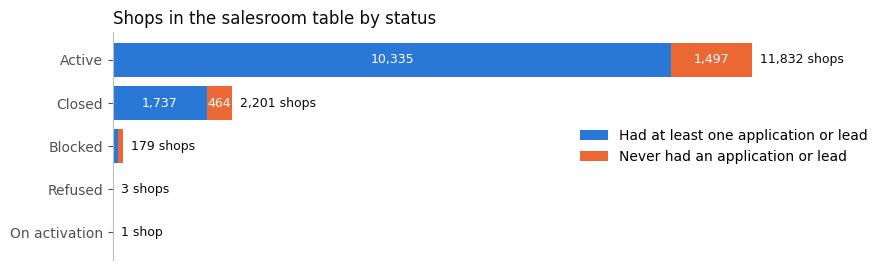

In [5]:
d = shop_tt.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(d.trang_thai, d.co_hoat_dong, color=BLUE, label='Had at least one application or lead')
ax.barh(d.trang_thai, d.chua_tung_co_ho_so_hay_lead, left=d.co_hoat_dong, color=ORANGE, label='Never had an application or lead')
for i, (a, b) in enumerate(zip(d.co_hoat_dong, d.chua_tung_co_ho_so_hay_lead)):
    ax.text(a + b, i, f'  {a + b:,.0f} shop' + ('s' if a + b != 1 else ''), va='center', color=INK, fontsize=9)
    if a > 1000: ax.text(a / 2, i, f'{a:,.0f}', va='center', ha='center', color='white', fontsize=9)
    if b > 400: ax.text(a + b / 2, i, f'{b:,.0f}', va='center', ha='center', color='white', fontsize=9)
bo_truc_x(ax); ax.set_xlim(0, d.so_shop.max() * 1.2)
ax.set_title('Shops in the salesroom table by status', loc='left', color=INK)
ax.legend(frameon=False, loc='center right')
plt.tight_layout(); luu_hinh(fig, 'b1_01_shop_status'); plt.show()


- 11.832 shop đang Active, nhưng 1.497 shop trong số đó chưa từng có một hồ sơ hay một lead nào kể từ khi bắt đầu hoạt động (cột `chua_tung_co_ho_so_hay_lead`).
- 3.828 shop Active là shop mới, trong đó 278 shop bắt đầu hoạt động sau 09/2026, tức sau tháng cuối có số liệu (cột `bat_dau_sau_09_2026`). Các shop này chưa có tháng nào để tính, nên Current Actual của chúng bằng 0.

Notebook tính cho mọi shop trong bảng salesroom, kể cả shop đã đóng, để tổng của từng tháng đầy đủ. Khi so sánh các shop với nhau, chỉ dùng shop Active.

## 1.3. Bán trực tiếp tại shop

Phần này đi theo công thức ở đầu notebook: trước hết tính các con số cho mỗi shop trong mỗi tháng, sau đó xem lần lượt số SA, số hồ sơ mỗi SA, tỷ lệ bị từ chối và tỷ lệ hủy.

Câu lệnh dưới đây tạo bảng `truc_tiep` từ các hồ sơ ghi tại shop trong bảng salesroom. Mỗi dòng là một shop trong một tháng nộp hồ sơ:
- `ho_so`: số hồ sơ khách nộp;
- `hd_ky`: số contract đã ký;
- `hs_tu_choi`, `hs_huy`: số hồ sơ bị công ty từ chối (trạng thái Rejected) và số hồ sơ bị hủy trước khi thành contract (trạng thái Cancelled);
- `so_sa`: số SA, tức số nhân viên khác nhau thực sự làm hồ sơ tại shop trong tháng (cột `skp_emp_pre_process`). Không đếm theo bảng phân công `emp_2_salesroom`, vì notebook EDA (mục 9.5) cho thấy một nhân viên thường được phân công cho nhiều shop hơn số shop người đó thực sự làm hồ sơ: đếm theo bảng phân công thì shop đứng giữa có 20 SA, đếm theo người làm hồ sơ thì chỉ có 1 SA;
- `so_tien`: funded volume (tổng tiền công ty cho khách vay) của các contract đã ký, giải thích kỹ ở phần tiền bên dưới;
- `tien_vay_tra_gop`, `hd_tra_gop`, `hd_bao_hiem`: tổng tiền vay, số contract, và số contract có mua bảo hiểm khoản vay (`ins_amount` lớn hơn 0), chỉ tính các sản phẩm có khoản vay cố định (CD, TW, CL, CW);
- `hd_tinh_rui_ro`, `hd_tre_han`: số contract dùng để đo rủi ro và số contract trong đó khách trễ hạn ít nhất một trong 4 kỳ trả đầu, giải thích ở phần rủi ro bên dưới.

Sau đó cộng toàn mạng lưới theo tháng, kèm tỷ lệ ký (`ty_le_ky` = contract / hồ sơ), tỷ lệ bị từ chối (`ty_le_tu_choi` = hồ sơ bị từ chối / hồ sơ) và tỷ lệ hủy (`ty_le_huy` = hồ sơ bị hủy / hồ sơ) của từng tháng.

In [6]:
con.execute(f'''create or replace temp table truc_tiep as
select skp_salesroom, apply_month thang,
  count(*) ho_so,
  sum(is_signed) hd_ky,
  count(*) filter (where name_status='Rejected') hs_tu_choi,
  count(*) filter (where name_status='Cancelled') hs_huy,
  sum(case when is_signed=1 then case when product in ('CC','BNPL')
      then coalesce(amt_billing_1st,0)+coalesce(amt_billing_2nd,0)+coalesce(amt_billing_3rd,0) else credit_amount end end) so_tien,
  sum(credit_amount) filter (where is_signed=1 and product in ('CD','TW','CL','CW')) tien_vay_tra_gop,
  count(*) filter (where is_signed=1 and product in ('CD','TW','CL','CW')) hd_tra_gop,
  count(*) filter (where is_signed=1 and product in ('CD','TW','CL','CW') and ins_amount>0) hd_bao_hiem,
  count(*) filter (where is_signed=1 and sign_month between '{RISK_FROM}' and '{RISK_TO}') hd_tinh_rui_ro,
  count(*) filter (where is_signed=1 and sign_month between '{RISK_FROM}' and '{RISK_TO}'
                   and greatest(dpd_1pd, dpd_2pd, dpd_3pd, dpd_4pd)=1) hd_tre_han,
  count(distinct skp_emp_pre_process) so_sa
from contract where skp_salesroom in (select skp_salesroom from salesroom) and apply_month<='{LAST_MONTH}'
group by all''')
mang_luoi = q('''select thang, count(*) so_shop, sum(ho_so) ho_so, sum(hd_ky) hd_ky, sum(hd_ky)/sum(ho_so) ty_le_ky,
  sum(hs_tu_choi)/sum(ho_so) ty_le_tu_choi, sum(hs_huy)/sum(ho_so) ty_le_huy, sum(so_tien)/1e9 so_tien_ty_dong
from truc_tiep group by 1 order by 1''')
mang_luoi

,thang,so_shop,ho_so,hd_ky,ty_le_ky,ty_le_tu_choi,ty_le_huy,so_tien_ty_dong
0,2025-01-01,189,"1,526",867,0.568,0.379,0.053,8.090
1,2025-02-01,325,"3,037","1,944",0.640,0.306,0.054,17.845
2,2025-03-01,730,"6,329","3,858",0.610,0.316,0.074,44.598
3,2025-04-01,1065,"9,331","5,372",0.576,0.355,0.070,57.984
4,2025-05-01,1393,"11,659","7,177",0.616,0.309,0.076,82.978
5,2025-06-01,1945,"15,819","10,133",0.641,0.294,0.065,115.2
6,2025-07-01,2511,"21,103","13,762",0.652,0.278,0.070,161.7
7,2025-08-01,2824,"23,940","15,979",0.667,0.266,0.066,192.8
8,2025-09-01,3057,"26,860","17,931",0.668,0.266,0.067,212.1
9,2025-10-01,3397,"31,368","20,642",0.658,0.272,0.070,261.5


Biểu đồ dưới đây vẽ hai cột `ty_le_tu_choi` và `ty_le_huy` của bảng trên theo tháng. Ảnh được lưu thành `Bước 1/hinh/b1_02_reject_cancel_month.png`.


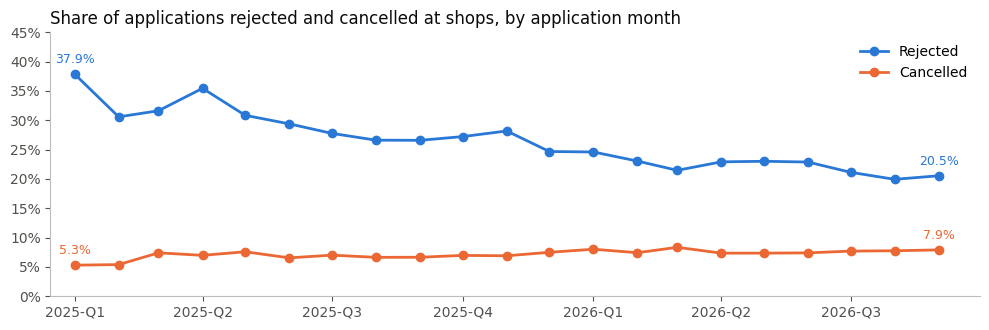

In [7]:
import matplotlib.dates as mdates
def truc_quy(a):
    # Trục hoành từ 01/2025 đến 09/2026, vạch chia ở tháng đầu mỗi quý, nhãn dạng 2025-Q1
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{mdates.num2date(x).year}-Q{(mdates.num2date(x).month - 1) // 3 + 1}'))
    a.set_xlim(pd.Timestamp('2024-12-15'), pd.Timestamp('2026-09-30'))

fig, ax = plt.subplots(figsize=(10, 3.4))
thang = pd.to_datetime(mang_luoi.thang)
ax.plot(thang, mang_luoi.ty_le_tu_choi, color=BLUE, marker='o', label='Rejected')
ax.plot(thang, mang_luoi.ty_le_huy, color=ORANGE, marker='o', label='Cancelled')
for cot, mau in [('ty_le_tu_choi', BLUE), ('ty_le_huy', ORANGE)]:
    for i in [0, len(mang_luoi) - 1]:
        ax.annotate(f'{mang_luoi[cot].iloc[i]:.1%}', (thang.iloc[i], mang_luoi[cot].iloc[i]), textcoords='offset points',
                    xytext=(0, 8), ha='center', color=mau, fontsize=9)
ax.set_ylim(0, 0.45); ax.yaxis.set_major_formatter(phan_tram()); ax.legend(frameon=False, loc='upper right')
truc_quy(ax)
ax.set_title('Share of applications rejected and cancelled at shops, by application month', loc='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_02_reject_cancel_month'); plt.show()


- Phần trăm hồ sơ thành contract (cột `ty_le_ky`) tăng từ 57–64% ở 6 tháng đầu năm 2025 lên 71–72% trong quý 3/2026.
- Mức tăng này đến hoàn toàn từ việc ít hồ sơ bị từ chối hơn: tỷ lệ bị từ chối giảm từ 29–38% (6 tháng đầu năm 2025) xuống 20–21% (quý 3/2026). Tỷ lệ hủy không giảm mà còn tăng nhẹ, từ 5–8% lên khoảng 8%.

Số contract là kết quả của số SA, số hồ sơ mỗi SA, và phần hồ sơ không bị từ chối hay bị hủy. Phần tiếp theo xem lần lượt từng con số.

### Số SA và số hồ sơ mỗi SA

Câu lệnh dưới đây lấy các shop có hồ sơ trong từng tháng của quý 3/2026, rồi chia số shop-tháng theo số SA làm hồ sơ (1, 2, 3, từ 4 trở lên), kèm số hồ sơ và số contract trung bình mỗi SA.

In [8]:
sa_nhom = q(f'''select case when so_sa>=4 then '4 trở lên' else so_sa::varchar end so_sa, count(*) so_shop_thang,
  count(*)/sum(count(*)) over () ty_trong, sum(ho_so)/sum(so_sa) ho_so_moi_sa, sum(hd_ky)/sum(so_sa) hd_moi_sa
from truc_tiep where thang between '{CA_FROM}' and '{CA_TO}' group by 1 order by 1''')
sa_nhom

,so_sa,so_shop_thang,ty_trong,ho_so_moi_sa,hd_moi_sa
0,1,12672,0.666,4.414,3.262
1,2,4007,0.211,4.925,3.569
2,3,1398,0.073,5.577,3.947
3,4 trở lên,954,0.050,7.993,5.481


Biểu đồ dưới đây vẽ lại bảng trên: bên trái là phần trăm số shop-tháng theo số SA, bên phải là số hồ sơ và số contract mỗi SA. Ảnh được lưu thành `Bước 1/hinh/b1_03_sa_per_shop.png`.

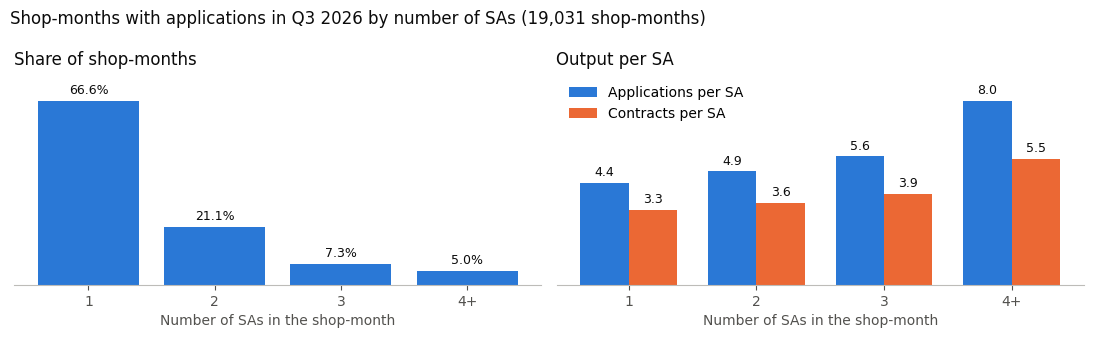

In [9]:
nhan = ['4+' if s == '4 trở lên' else s for s in sa_nhom.so_sa]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
t = ax[0].bar(nhan, sa_nhom.ty_trong, color=BLUE); ghi_so(ax[0], t, '{:.1%}')
ax[0].set_title('Share of shop-months', loc='left', color=INK)
x = np.arange(len(nhan)); w = 0.38
t1 = ax[1].bar(x - w / 2, sa_nhom.ho_so_moi_sa, w, color=BLUE, label='Applications per SA'); ghi_so(ax[1], t1, '{:.1f}')
t2 = ax[1].bar(x + w / 2, sa_nhom.hd_moi_sa, w, color=ORANGE, label='Contracts per SA'); ghi_so(ax[1], t2, '{:.1f}')
ax[1].set_xticks(x); ax[1].set_xticklabels(nhan); ax[1].legend(frameon=False, loc='upper left')
ax[1].set_title('Output per SA', loc='left', color=INK)
for a in ax: bo_truc_y(a); a.margins(y=0.15); a.set_xlabel('Number of SAs in the shop-month')
fig.suptitle(f'Shop-months with applications in Q3 2026 by number of SAs ({sa_nhom.so_shop_thang.sum():,} shop-months)', x=0.01, ha='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_03_sa_per_shop'); plt.show()


- 2/3 số shop-tháng chỉ có đúng 1 SA làm hồ sơ (12.672 shop-tháng, tức 66,6%). Chỉ 5% có từ 4 SA trở lên.
- Shop có nhiều SA thì mỗi SA cũng làm nhiều hồ sơ hơn: 4,4 hồ sơ mỗi SA khi shop có 1 SA, lên 8,0 hồ sơ mỗi SA khi shop có từ 4 SA. Điều này cho thấy shop nhiều SA thường là shop đông khách. Nó chưa chứng minh được rằng cứ thêm SA thì shop sẽ có thêm khách, vì cũng có thể shop đông khách nên mới có nhiều SA.

Câu lệnh dưới đây kiểm tra số SA có giá trị bất thường không: mức mà 99% số shop-tháng trong quý 3/2026 không vượt quá, và danh sách các shop-tháng có từ 20 SA trở lên.

In [10]:
display(q(f'''select count(*) so_shop_thang, quantile_cont(so_sa, 0.99) muc_99, max(so_sa) lon_nhat
from truc_tiep where thang between '{CA_FROM}' and '{CA_TO}' '''))
q(f'''select t.skp_salesroom, t.thang, s.salesroom_category, s.salesroom_product, s.salesroom_model, s.shop_moi,
  t.so_sa, t.ho_so, t.hd_ky, t.ho_so/t.so_sa ho_so_moi_sa
from truc_tiep t join shop s using(skp_salesroom)
where t.thang between '{CA_FROM}' and '{CA_TO}' and t.so_sa>=20 order by t.so_sa desc, t.skp_salesroom, t.thang''')

,so_shop_thang,muc_99,lon_nhat
0,19031,6,168


,skp_salesroom,thang,salesroom_category,salesroom_product,salesroom_model,shop_moi,so_sa,ho_so,hd_ky,ho_so_moi_sa
0,126511988,2026-08-01,Big,CD,Aldi,1,168,521,346,3.101
1,118655027,2026-09-01,Big,CD,Aldi,0,25,530,351,21.200
2,101003268,2026-09-01,Small,CD,Aldi,0,23,342,245,14.870
3,106742885,2026-09-01,Small,CD,Aldi,0,23,335,210,14.565
4,101003268,2026-08-01,Small,CD,Aldi,0,21,293,224,13.952
5,106742885,2026-08-01,Small,CD,Aldi,0,20,260,160,13


- 99% số shop-tháng có không quá 6 SA, nhưng có 6 shop-tháng từ 20 SA trở lên. Cả 6 đều là shop CD kiểu Aldi, tức nhân viên của chính cửa hàng làm hồ sơ. Ở các shop này, số người làm hồ sơ là số nhân viên cửa hàng, không phải số SA do công ty cử đến.
- Shop 126511988 có 168 người làm hồ sơ trong tháng 08/2026 cho 521 hồ sơ, tức 3,1 hồ sơ mỗi người, trong khi các shop CD Aldi lớn còn lại trong danh sách có 13–21 hồ sơ mỗi người. Đây là shop mới (`shop_moi` bằng 1). Số liệu được giữ nguyên, nhưng với shop này số hồ sơ mỗi SA không phản ánh năng suất thật.

Vì số SA ở shop Aldi và shop Non-Aldi đo hai thứ khác nhau, khi so số SA và số hồ sơ mỗi SA chỉ nên so các shop cùng kiểu làm hồ sơ.

### Tỷ lệ bị từ chối và tỷ lệ hủy của từng shop

Câu lệnh dưới đây kiểm tra trước: hồ sơ tại shop có những trạng thái nào. Nếu chỉ có trạng thái đã ký, Rejected và Cancelled thì tỷ lệ ký + tỷ lệ bị từ chối + tỷ lệ hủy luôn bằng 100%.

In [11]:
trang_thai_hs = q(f'''select name_status, is_signed, count(*) ho_so, count(*)/sum(count(*)) over () ty_trong
from contract where skp_salesroom in (select skp_salesroom from salesroom) and apply_month<='{LAST_MONTH}'
group by all order by 3 desc''')
trang_thai_hs

,name_status,is_signed,ho_so,ty_trong
0,Active,1,253982,0.409
1,Finished,1,162982,0.262
2,Rejected,0,149105,0.240
3,Cancelled,0,46256,0.074
4,Written off,1,6207,0.010
5,Paid off,1,2814,0.005
6,Signed,1,41,0.000


Biểu đồ dưới đây vẽ lại bảng trên: phần trăm hồ sơ theo trạng thái, màu xanh là trạng thái đã ký, màu cam là chưa thành contract. Ảnh được lưu thành `Bước 1/hinh/b1_04_application_status.png`.

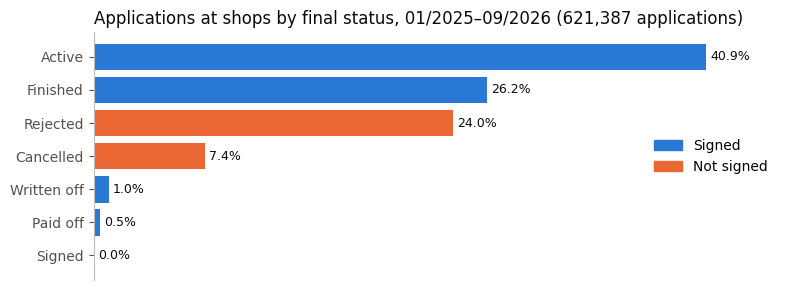

In [12]:
from matplotlib.patches import Patch
d = trang_thai_hs.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3))
t = ax.barh(d.name_status, d.ty_trong, color=[BLUE if k == 1 else ORANGE for k in d.is_signed]); ghi_so(ax, t, '{:.1%}')
bo_truc_x(ax); ax.margins(x=0.12)
ax.legend(handles=[Patch(color=BLUE, label='Signed'), Patch(color=ORANGE, label='Not signed')], frameon=False, loc='center right')
ax.set_title(f'Applications at shops by final status, 01/2025–09/2026 ({trang_thai_hs.ho_so.sum():,} applications)', loc='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_04_application_status'); plt.show()


Hồ sơ tại shop chỉ có ba loại: đã ký (Active, Finished, Written off, Paid off, Signed), Rejected (24,0%) và Cancelled (7,4%). Vì vậy với mọi shop, tỷ lệ ký = 1 − tỷ lệ bị từ chối − tỷ lệ hủy.

Câu lệnh dưới đây tính tỷ lệ bị từ chối và tỷ lệ hủy của từng shop Active trong quý 3/2026 (tổng của 3 tháng), rồi xem phân bố theo ngành hàng và kiểu làm hồ sơ: mức 25%, trung vị, mức 75%. Chỉ lấy shop có từ 10 hồ sơ trong quý, vì với shop có 1–2 hồ sơ, tỷ lệ chỉ có thể là 0%, 50% hoặc 100%.

In [13]:
ty_le_nhom = q(f'''with s as (select skp_salesroom, sum(ho_so) hs, sum(hs_tu_choi)/sum(ho_so) tc, sum(hs_huy)/sum(ho_so) huy from truc_tiep
   where thang between '{CA_FROM}' and '{CA_TO}' group by 1)
select sh.salesroom_product || ' ' || sh.salesroom_model nhom_shop, count(*) so_shop_tu_10_ho_so,
  quantile_cont(tc, 0.25) tu_choi_muc_25, median(tc) tu_choi_trung_vi, quantile_cont(tc, 0.75) tu_choi_muc_75,
  quantile_cont(huy, 0.25) huy_muc_25, median(huy) huy_trung_vi, quantile_cont(huy, 0.75) huy_muc_75
from s join shop sh using(skp_salesroom)
where s.hs>=10 and sh.salesroom_status='Active' group by 1 order by 1''')
ty_le_nhom

,nhom_shop,so_shop_tu_10_ho_so,tu_choi_muc_25,tu_choi_trung_vi,tu_choi_muc_75,huy_muc_25,huy_trung_vi,huy_muc_75
0,CD Aldi,38,0.199,0.224,0.279,0.072,0.098,0.128
1,CD Non-Aldi,1846,0.107,0.200,0.300,0.014,0.062,0.105
2,NS Aldi,899,0.125,0.214,0.306,0.024,0.067,0.120
3,TW Non-Aldi,672,0,0.050,0.094,0.023,0.071,0.111


Biểu đồ dưới đây vẽ lại bảng trên: chấm tròn là shop đứng giữa (trung vị), đoạn ngang chạy từ mức 25% đến mức 75%, tức nửa số shop ở giữa. Ảnh được lưu thành `Bước 1/hinh/b1_05_reject_cancel_spread.png`.

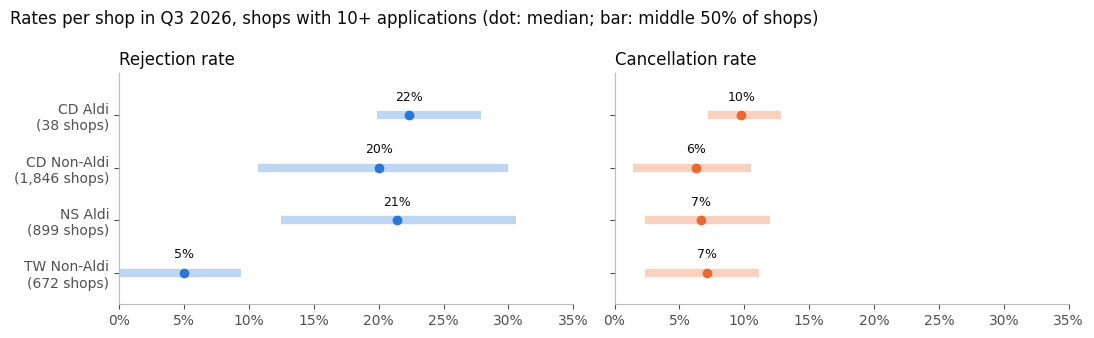

In [14]:
nhan = [f'{g}\n({n:,} shops)' for g, n in zip(ty_le_nhom.nhom_shop, ty_le_nhom.so_shop_tu_10_ho_so)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
ve_khoang(ax[0], nhan, ty_le_nhom.tu_choi_trung_vi, ty_le_nhom.tu_choi_muc_25, ty_le_nhom.tu_choi_muc_75)
ve_khoang(ax[1], nhan, ty_le_nhom.huy_trung_vi, ty_le_nhom.huy_muc_25, ty_le_nhom.huy_muc_75, mau=ORANGE)
ax[0].set_title('Rejection rate', loc='left', color=INK); ax[1].set_title('Cancellation rate', loc='left', color=INK)
for a in ax: a.xaxis.set_major_formatter(phan_tram()); a.set_xlim(0, 0.35)
fig.suptitle('Rates per shop in Q3 2026, shops with 10+ applications (dot: median; bar: middle 50% of shops)', x=0.01, ha='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_05_reject_cancel_spread'); plt.show()


- Tỷ lệ bị từ chối cao hơn nhiều so với tỷ lệ hủy. Ở shop đứng giữa, 20–22% hồ sơ bị từ chối với shop CD và NS, nhưng chỉ 5% với shop TW. Tỷ lệ hủy của shop đứng giữa chỉ khoảng 6–10%.
- Trong cùng loại shop, các shop chênh nhau nhiều. Với shop CD Non-Aldi, 1/4 số shop có tỷ lệ bị từ chối dưới 10,7%, trong khi 1/4 số shop trên 30%. Tỷ lệ hủy cũng vậy: dưới 1,4% ở 1/4 số shop tốt nhất, trên 10,5% ở 1/4 số shop kém nhất.

Hai tỷ lệ này cho biết hai việc khác nhau. Hồ sơ bị từ chối là do công ty không đồng ý cho khách vay, nên giảm tỷ lệ này nghĩa là duyệt thêm khách và cần xem rủi ro trước. Hồ sơ bị hủy là khách đã đến shop nhưng không đi tới ký (khách đổi ý, thiếu giấy tờ), nên đây là phần SA có thể giữ lại bằng cách theo sát khách.

### Contract mang lại bao nhiêu tiền

Funded volume là tổng tiền công ty cho khách vay. Với các sản phẩm có khoản vay cố định (CD, TW, CL, CW), con số này là cột `credit_amount`. Với Credit Card (CC) và BNPL, cột `credit_amount` gần như luôn bằng 0 vì khách được cấp một hạn mức rồi tiêu dần, nên notebook dùng tổng số tiền khách tiêu trong 3 kỳ bảng kê đầu (`amt_billing_1st`, `amt_billing_2nd`, `amt_billing_3rd`).

Câu lệnh dưới đây xem trong quý 3/2026, tại các shop trong bảng, mỗi sản phẩm có bao nhiêu contract, bao nhiêu tiền, và số tiền trung bình mỗi contract.

In [15]:
sp_tien = q(f'''select product san_pham, count(*) hd_ky,
  sum(case when product in ('CC','BNPL') then coalesce(amt_billing_1st,0)+coalesce(amt_billing_2nd,0)+coalesce(amt_billing_3rd,0)
      else credit_amount end)/1e9 so_tien_ty_dong,
  so_tien_ty_dong*1e9/hd_ky/1e6 trieu_dong_moi_hd
from contract where is_signed=1 and skp_salesroom in (select skp_salesroom from salesroom)
  and apply_month between '{CA_FROM}' and '{CA_TO}' group by 1 order by 2 desc''')
sp_tien

,san_pham,hd_ky,so_tien_ty_dong,trieu_dong_moi_hd
0,CD,82754,942.4,11.388
1,TW,17994,387.4,21.528
2,BNPL,7723,15.367,1.990
3,CL,5065,217.2,42.877
4,CC,1613,19.536,12.111
5,CW,589,12.815,21.757


Biểu đồ dưới đây vẽ lại bảng trên: số contract và số tiền trung bình mỗi contract của từng sản phẩm. Ảnh được lưu thành `Bước 1/hinh/b1_06_product_amount.png`.

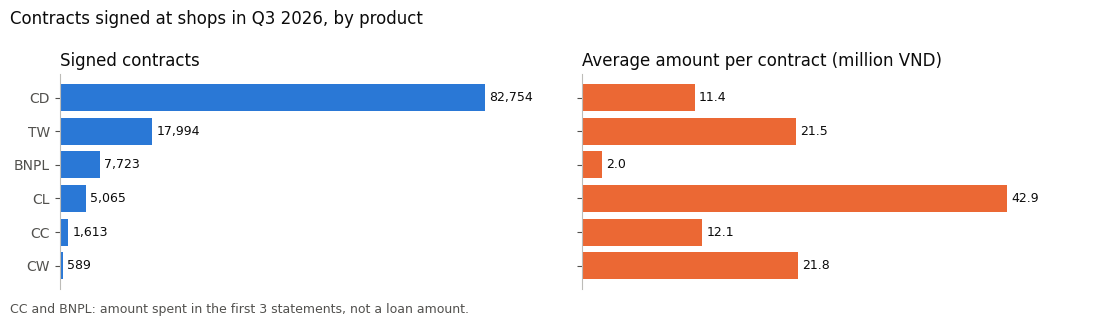

In [16]:
d = sp_tien.iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
t = ax[0].barh(d.san_pham, d.hd_ky, color=BLUE); ghi_so(ax[0], t, '{:,.0f}')
t = ax[1].barh(d.san_pham, d.trieu_dong_moi_hd, color=ORANGE); ghi_so(ax[1], t, '{:.1f}')
ax[0].set_title('Signed contracts', loc='left', color=INK)
ax[1].set_title('Average amount per contract (million VND)', loc='left', color=INK)
for a in ax: bo_truc_x(a); a.margins(x=0.18)
fig.suptitle('Contracts signed at shops in Q3 2026, by product', x=0.01, ha='left', color=INK)
fig.text(0.01, -0.03, 'CC and BNPL: amount spent in the first 3 statements, not a loan amount.', color=MUTED, fontsize=9)
plt.tight_layout(); luu_hinh(fig, 'b1_06_product_amount'); plt.show()


Số tiền mỗi contract khác nhau rất nhiều giữa các sản phẩm: khoảng 11 triệu đồng với CD, 22 triệu với TW, 43 triệu với CL. Với BNPL và CC, con số chỉ là số tiền khách tiêu trong 3 kỳ bảng kê đầu, không phải khoản vay. Vì vậy một shop xe máy thường có funded volume lớn hơn một shop điện thoại dù bán cùng số contract. Đây là lý do nhóm chọn số contract làm thước đo doanh số chính để so các shop, còn funded volume đi kèm để tham khảo.

### Khách mua nhóm hàng gì

Bảng `contract_product` cho biết khách vay để mua món hàng gì (cột `goods_group_clean`). Trước khi nối bảng này vào contract, câu lệnh dưới đây kiểm tra mỗi hồ sơ chỉ có một dòng trong bảng, để việc nối không làm số contract bị nhân lên.

In [17]:
q('select count(*) so_dong, count(distinct skp_credit_case) so_ho_so_khac_nhau from contract_product')

,so_dong,so_ho_so_khac_nhau
0,779941,779941


Số dòng bằng số hồ sơ khác nhau, nên nối không làm nhân dòng.

Câu lệnh dưới đây đếm, trong quý 3/2026, số contract đã ký tại shop theo ngành hàng chính của shop và nhóm hàng, rồi tính tỷ trọng của mỗi nhóm hàng trong ngành hàng đó. Chỉ hiện các nhóm chiếm từ 2% trở lên. Contract CL, CC, BNPL và CW không có dòng trong bảng `contract_product` (khách vay tiền hoặc dùng thẻ, không mua một món hàng cụ thể), nên được xếp vào nhóm "Không gắn món hàng".

In [18]:
con.execute(f'''create or replace temp table mix as
select c.skp_salesroom, coalesce(p.goods_group_clean, 'Không gắn món hàng') nhom_hang, count(*) hd_ky
from contract c left join contract_product p using(skp_credit_case)
where c.is_signed=1 and c.skp_salesroom in (select skp_salesroom from salesroom) and c.apply_month between '{CA_FROM}' and '{CA_TO}'
group by all''')
mix_nganh = q('''with t as (select s.salesroom_product nganh_hang_shop, m.nhom_hang, sum(m.hd_ky) hd_ky from mix m join shop s using(skp_salesroom) group by all)
select *, hd_ky/sum(hd_ky) over (partition by nganh_hang_shop) ty_trong from t
qualify ty_trong>=0.02 order by nganh_hang_shop, hd_ky desc''')
mix_nganh

,nganh_hang_shop,nhom_hang,hd_ky,ty_trong
0,CD,Mobile,"35,994",0.552
1,CD,Không gắn món hàng,"10,025",0.154
2,CD,Home Appliances,"7,935",0.122
3,CD,Others,"6,995",0.107
4,CD,Notebook,"2,093",0.032
5,CD,Audio-Video,"2,067",0.032
6,NS,Healthcare,"10,913",0.387
7,NS,Fitness,"10,474",0.372
8,NS,Furniture,"4,234",0.150
9,NS,Education,"1,746",0.062


Biểu đồ dưới đây vẽ lại bảng trên, mỗi ngành hàng của shop một ô. Ảnh được lưu thành `Bước 1/hinh/b1_07_goods_mix.png`.

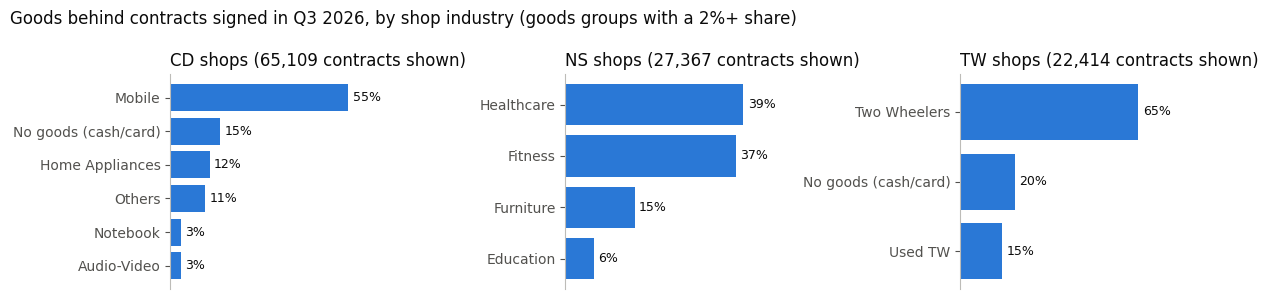

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, (ng, d) in zip(ax, mix_nganh.groupby('nganh_hang_shop')):
    d = d.sort_values('ty_trong')
    t = a.barh(d.nhom_hang.replace({'Không gắn món hàng': 'No goods (cash/card)'}), d.ty_trong, color=BLUE); ghi_so(a, t, '{:.0%}')
    a.set_title(f'{ng} shops ({int(d.hd_ky.sum()):,} contracts shown)', loc='left', color=INK); bo_truc_x(a); a.margins(x=0.25)
fig.suptitle('Goods behind contracts signed in Q3 2026, by shop industry (goods groups with a 2%+ share)', x=0.01, ha='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_07_goods_mix'); plt.show()


Shop CD phụ thuộc nhiều vào điện thoại (55% contract), còn shop NS chia gần đều giữa chăm sóc sức khỏe (39%) và gym (37%). File `Bước 1/shop_goods_mix.csv` lưu cơ cấu này cho từng shop, để xem shop nào đang phụ thuộc vào một nhóm hàng.

### Khách có mua bảo hiểm khoản vay không

Bảo hiểm khoản vay là sản phẩm bán kèm khi khách ký contract. Câu lệnh dưới đây tính, trong quý 3/2026, tỷ lệ contract trả góp (CD, TW, CL, CW) có mua bảo hiểm, chia theo ngành hàng chính của shop và kiểu làm hồ sơ (`salesroom_model`):
- Aldi: nhân viên của chính cửa hàng tự làm hồ sơ vay cho khách;
- Non-Aldi: công ty cử SA đến shop để làm hồ sơ.

Ngoài tỷ lệ chung, câu lệnh đếm số shop gần như không bán bảo hiểm (dưới 5% contract có bảo hiểm) và số shop gần như contract nào cũng có bảo hiểm (trên 95%).

,nhom_shop,so_shop,hd_tra_gop,ty_le_bao_hiem,shop_duoi_5pct,shop_tren_95pct
0,CD Aldi,39,"8,537",0.002,36,0
1,CD Non-Aldi,4128,"50,416",0.872,34,3758
2,NS Aldi,2017,"27,624",0.536,909,917
3,TW Non-Aldi,1601,"19,825",0.801,83,1161


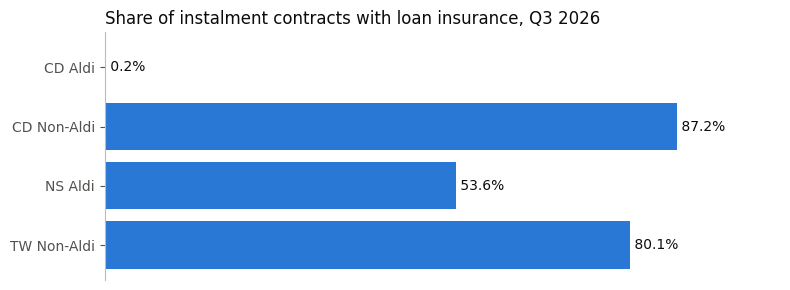

In [20]:
bao_hiem = q(f'''with s as (select t.skp_salesroom, sum(hd_tra_gop) n, sum(hd_bao_hiem) bh from truc_tiep t
   where thang between '{CA_FROM}' and '{CA_TO}' group by 1 having sum(hd_tra_gop)>0)
select sh.salesroom_product || ' ' || sh.salesroom_model nhom_shop, count(*) so_shop, sum(n) hd_tra_gop,
  sum(bh)/sum(n) ty_le_bao_hiem, count(*) filter (where bh/n<0.05) shop_duoi_5pct, count(*) filter (where bh/n>0.95) shop_tren_95pct
from s join shop sh using(skp_salesroom) group by 1 order by 1''')
display(bao_hiem)
ve_cot_ngang(bao_hiem.nhom_shop.tolist(), bao_hiem.ty_le_bao_hiem.tolist(),
             'Share of instalment contracts with loan insurance, Q3 2026', '{:.1%}', ten='b1_08_insurance')

- Khách có mua bảo hiểm hay không khác hẳn theo kiểu làm hồ sơ. Ở shop CD Non-Aldi, nơi SA của công ty làm hồ sơ, 87,2% contract có bảo hiểm, và 3.758 trên 4.128 shop gần như contract nào cũng có. Ở shop CD Aldi, nơi nhân viên cửa hàng làm hồ sơ, chỉ 0,2% contract có bảo hiểm, và 36 trên 39 shop gần như không bán bảo hiểm.
- Shop CD Aldi ít nhưng lớn: 39 shop có 8.537 contract trả góp trong quý, tức khoảng 219 contract mỗi shop (8.537 / 39 ≈ 219), so với khoảng 12 ở shop CD Non-Aldi (50.416 / 4.128 ≈ 12).
- Shop NS (trong bảng chỉ có kiểu Aldi) chia thành hai nhóm gần bằng nhau: 909 shop gần như không bán bảo hiểm và 917 shop gần như contract nào cũng có. Tỷ lệ chung 53,6% là kết quả của hai nhóm này, không phải mức của một shop điển hình.

Bảng này chưa cho biết vì sao các shop khác nhau như vậy, nhưng cho thấy một khoản bán kèm đáng chú ý: ở shop CD Aldi và khoảng một nửa số shop NS, gần như không contract nào có bảo hiểm.

### Khách có trả nợ đúng hạn không

Mỗi contract có 4 cột `dpd_1pd` đến `dpd_4pd`, bằng 1 nếu khách trễ hạn ở kỳ trả thứ 1 đến thứ 4. Rủi ro của shop được đo bằng **tỷ lệ contract có khách trễ hạn ít nhất một trong 4 kỳ đầu**, để thấy khách có trả đều không chứ không chỉ kỳ đầu. Chỉ dùng contract ký từ 03/2025 đến hết 05/2026: Bước 0 (mục 0.5) cho thấy contract ký 01–02/2025 có tỷ lệ trễ thấp khác thường, còn contract ký từ 06/2026 chưa đến đủ 4 kỳ trả.

Câu lệnh dưới đây tính, theo ngành hàng chính của shop, tỷ lệ trễ của từng kỳ và tỷ lệ trễ ít nhất một trong 4 kỳ (`tre_it_nhat_1_ky`).

In [21]:
rr_nganh = q(f'''select s.salesroom_product nganh_hang_shop, count(*) hd_tinh_rui_ro, avg(dpd_1pd) ky_1, avg(dpd_2pd) ky_2, avg(dpd_3pd) ky_3, avg(dpd_4pd) ky_4,
  avg(greatest(dpd_1pd, dpd_2pd, dpd_3pd, dpd_4pd)) tre_it_nhat_1_ky
from contract c join shop s using(skp_salesroom)
where c.is_signed=1 and c.sign_month between '{RISK_FROM}' and '{RISK_TO}' group by 1 order by 1''')
rr_nganh

,nganh_hang_shop,hd_tinh_rui_ro,ky_1,ky_2,ky_3,ky_4,tre_it_nhat_1_ky
0,CD,156544,0.098,0.133,0.138,0.141,0.277
1,NS,65576,0.131,0.170,0.171,0.176,0.341
2,TW,53645,0.093,0.127,0.134,0.142,0.268


Biểu đồ dưới đây vẽ lại bảng trên: tỷ lệ contract trễ hạn ở từng kỳ trả 1 đến 4, mỗi ngành hàng một đường; chú thích ghi tỷ lệ trễ ít nhất một trong 4 kỳ. Ảnh được lưu thành `Bước 1/hinh/b1_09_late_by_instalment.png`.

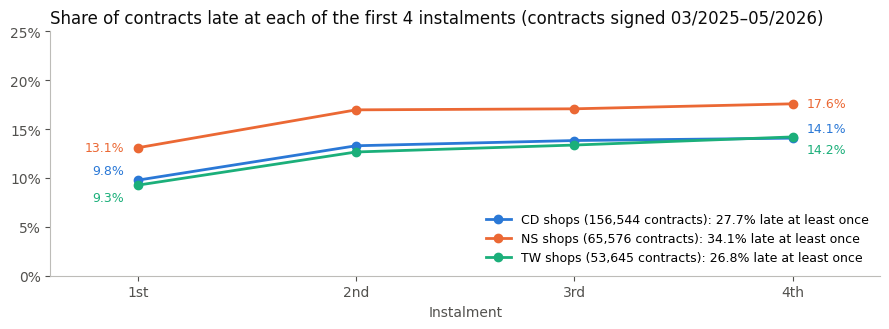

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for (_, r), mau in zip(rr_nganh.iterrows(), [BLUE, ORANGE, GREEN]):
    y = [r.ky_1, r.ky_2, r.ky_3, r.ky_4]
    ax.plot([1, 2, 3, 4], y, marker='o', color=mau,
            label=f'{r.nganh_hang_shop} shops ({r.hd_tinh_rui_ro:,} contracts): {r.tre_it_nhat_1_ky:.1%} late at least once')
    lech = {'CD': 7, 'NS': 0, 'TW': -9}.get(r.nganh_hang_shop, 0)   # dịch nhãn lên/xuống để hai đường gần nhau không đè chữ
    for xi, yi in zip([1, 4], [y[0], y[-1]]):
        ax.annotate(f'{yi:.1%}', (xi, yi), textcoords='offset points', xytext=(10 if xi == 4 else -10, lech),
                    ha='left' if xi == 4 else 'right', va='center', color=mau, fontsize=9)
ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(['1st', '2nd', '3rd', '4th']); ax.set_xlabel('Instalment')
ax.set_xlim(0.6, 4.4); ax.set_ylim(0, 0.25); ax.yaxis.set_major_formatter(phan_tram())
ax.legend(frameon=False, loc='lower right', fontsize=9)
ax.set_title('Share of contracts late at each of the first 4 instalments (contracts signed 03/2025–05/2026)', loc='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_09_late_by_instalment'); plt.show()


Tỷ lệ trễ hạn của một shop nhỏ dễ dao động mạnh vì có ít contract. Câu lệnh dưới đây đếm, trong các shop Active, bao nhiêu shop có từ 30 contract trong nhóm tính rủi ro, và với các shop đó, tỷ lệ trễ hạn phân bố ra sao (mức 10%, 25%, 50%, 75%, 90%).

In [23]:
rr_phan_bo = q('''with r as (select skp_salesroom, sum(hd_tinh_rui_ro) n, sum(hd_tre_han)/nullif(sum(hd_tinh_rui_ro),0) tl
  from truc_tiep group by 1)
select count(*) filter (where n>0) shop_co_hd_tinh_rui_ro, count(*) filter (where n>=30) shop_du_30_hd,
  quantile_cont(tl, 0.1) filter (where n>=30) muc_10, quantile_cont(tl, 0.25) filter (where n>=30) muc_25,
  median(tl) filter (where n>=30) trung_vi, quantile_cont(tl, 0.75) filter (where n>=30) muc_75,
  quantile_cont(tl, 0.9) filter (where n>=30) muc_90
from r join shop s using(skp_salesroom) where s.salesroom_status='Active' ''')
rr_phan_bo

,shop_co_hd_tinh_rui_ro,shop_du_30_hd,muc_10,muc_25,trung_vi,muc_75,muc_90
0,6751,1757,0.167,0.212,0.275,0.364,0.449


Biểu đồ dưới đây vẽ phân bố tỷ lệ trễ hạn của các shop Active có từ 30 contract tính rủi ro, mỗi cột là một khoảng 2,5 điểm phần trăm; ba đường đứt là mức 10%, trung vị và mức 90% của bảng trên. Ảnh được lưu thành `Bước 1/hinh/b1_10_late_rate_spread.png`.

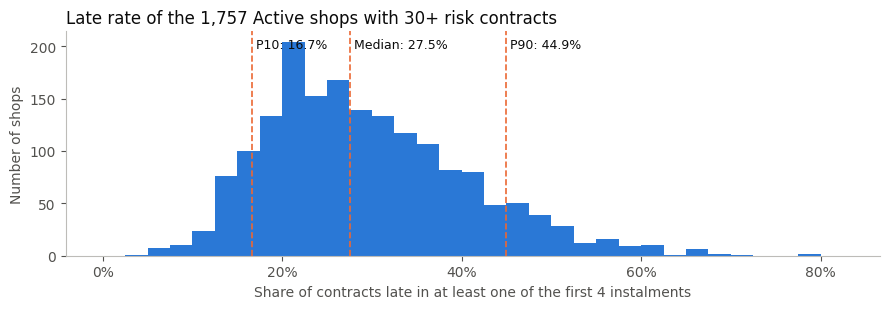

In [24]:
tl = q('''select sum(t.hd_tre_han)/sum(t.hd_tinh_rui_ro) tl from truc_tiep t join shop s using(skp_salesroom)
   where s.salesroom_status='Active' group by t.skp_salesroom having sum(t.hd_tinh_rui_ro)>=30''').tl
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(tl, bins=np.arange(0, 0.85, 0.025), color=BLUE)
tren = ax.get_ylim()[1]
for p, ten in [(0.1, 'P10'), (0.5, 'Median'), (0.9, 'P90')]:
    v = tl.quantile(p); ax.axvline(v, color=ORANGE, lw=1.2, ls='--')
    ax.text(v, tren * 0.97, f' {ten}: {v:.1%}', color=INK, fontsize=9, va='top')
ax.xaxis.set_major_formatter(phan_tram()); ax.set_ylabel('Number of shops')
ax.set_xlabel('Share of contracts late in at least one of the first 4 instalments')
ax.set_title(f'Late rate of the {len(tl):,} Active shops with 30+ risk contracts', loc='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_10_late_rate_spread'); plt.show()


- Nhìn cả 4 kỳ, khách trễ hạn nhiều hơn hẳn so với chỉ nhìn kỳ đầu: 27,7% contract của shop CD có khách trễ ít nhất một trong 4 kỳ, trong khi kỳ 1 chỉ 9,8%. Ở cả ba ngành hàng, tỷ lệ trễ tăng dần từ kỳ 1 đến kỳ 4.
- Shop NS có tỷ lệ trễ cao nhất: 34,1%, so với 27,7% ở shop CD và 26,8% ở shop TW.
- 6.751 shop Active có contract trong nhóm tính rủi ro, nhưng chỉ 1.757 shop có từ 30 contract trở lên. Với các shop có ít contract, tỷ lệ trễ hạn chưa đủ tin cậy: shop có 5 contract mà 1 khách trễ hạn thì tỷ lệ đã là 20%.
- Với 1.757 shop có đủ 30 contract, tỷ lệ trễ hạn chênh nhau rất nhiều: 1/10 số shop dưới 16,7%, shop đứng giữa 27,5%, và 1/10 số shop trên 44,9%.

Như vậy rủi ro khác nhau rõ giữa các shop. Một shop có nhiều khách trễ hạn thì không nên giảm tỷ lệ bị từ chối, tức không nên duyệt dễ hơn.

Câu lệnh dưới đây kiểm tra xem shop từ chối nhiều hồ sơ hơn có phải là shop có khách trả nợ kém hơn không. Lấy các shop Active có từ 10 hồ sơ trong quý 3/2026 và từ 30 contract tính rủi ro, chia thành 4 nhóm bằng nhau theo tỷ lệ bị từ chối (nhóm 1 thấp nhất), rồi tính tỷ lệ contract có khách trễ hạn trong 4 kỳ đầu của mỗi nhóm. Làm tương tự với tỷ lệ hủy.

In [25]:
tu_choi_tre = q(f'''with s as (select skp_salesroom, sum(ho_so) hs, sum(hs_tu_choi)/sum(ho_so) tc, sum(hs_huy)/sum(ho_so) huy from truc_tiep
   where thang between '{CA_FROM}' and '{CA_TO}' group by 1),
r as (select skp_salesroom, sum(hd_tinh_rui_ro) n, sum(hd_tre_han) tre from truc_tiep group by 1),
x as (select *, ntile(4) over (order by tc, skp_salesroom) nhom_tc, ntile(4) over (order by huy, skp_salesroom) nhom_huy
   from s join r using(skp_salesroom) join shop sh using(skp_salesroom) where hs>=10 and n>=30 and sh.salesroom_status='Active')
select 'theo tỷ lệ bị từ chối' chia, nhom_tc nhom, count(*) so_shop, avg(tc) tu_choi_tb, avg(huy) huy_tb, sum(tre)/sum(n) ty_le_tre from x group by 2
union all select 'theo tỷ lệ hủy', nhom_huy, count(*), avg(tc), avg(huy), sum(tre)/sum(n) from x group by 2 order by 1 desc, 2''')
tu_choi_tre

,chia,nhom,so_shop,tu_choi_tb,huy_tb,ty_le_tre
0,theo tỷ lệ hủy,1,367,0.183,0.006,0.286
1,theo tỷ lệ hủy,2,367,0.198,0.045,0.265
2,theo tỷ lệ hủy,3,367,0.170,0.081,0.281
3,theo tỷ lệ hủy,4,366,0.173,0.164,0.282
4,theo tỷ lệ bị từ chối,1,367,0.033,0.079,0.269
5,theo tỷ lệ bị từ chối,2,367,0.119,0.076,0.283
6,theo tỷ lệ bị từ chối,3,367,0.213,0.073,0.273
7,theo tỷ lệ bị từ chối,4,366,0.360,0.068,0.283


Biểu đồ dưới đây vẽ lại cột `ty_le_tre` của bảng trên: bên trái chia shop theo tỷ lệ bị từ chối, bên phải theo tỷ lệ hủy; dưới mỗi cột là nhóm và tỷ lệ trung bình của nhóm đó. Ảnh được lưu thành `Bước 1/hinh/b1_11_late_vs_reject_cancel.png`.

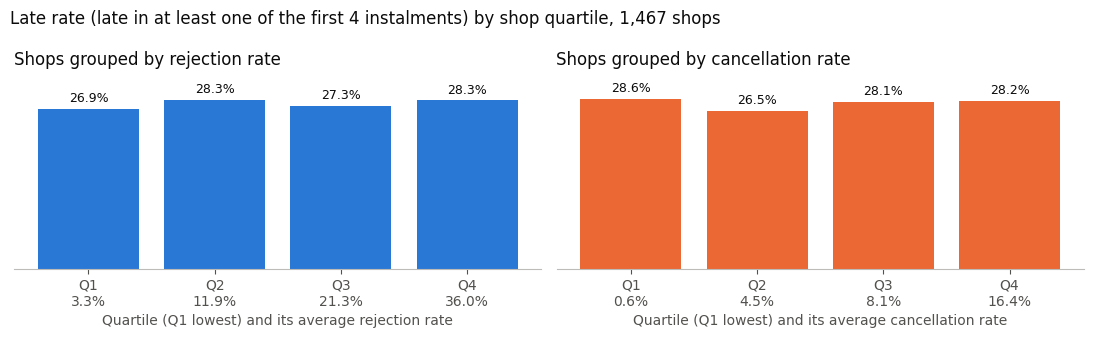

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, chia, cot, ten, mau in [(ax[0], 'theo tỷ lệ bị từ chối', 'tu_choi_tb', 'rejection', BLUE),
                               (ax[1], 'theo tỷ lệ hủy', 'huy_tb', 'cancellation', ORANGE)]:
    d = tu_choi_tre[tu_choi_tre.chia == chia].sort_values('nhom')
    t = a.bar([f'Q{n}\n{r:.1%}' for n, r in zip(d.nhom, d[cot])], d.ty_le_tre, color=mau); ghi_so(a, t, '{:.1%}')
    a.set_title(f'Shops grouped by {ten} rate', loc='left', color=INK)
    a.set_xlabel(f'Quartile (Q1 lowest) and its average {ten} rate'); bo_truc_y(a); a.margins(y=0.15)
so_shop = tu_choi_tre[tu_choi_tre.chia == 'theo tỷ lệ hủy'].so_shop.sum()
fig.suptitle(f'Late rate (late in at least one of the first 4 instalments) by shop quartile, {so_shop:,} shops', x=0.01, ha='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_11_late_vs_reject_cancel'); plt.show()


- Chia theo tỷ lệ bị từ chối, 4 nhóm shop có tỷ lệ trễ hạn gần như bằng nhau: 26,9–28,3%, dù nhóm thấp nhất chỉ từ chối 3,3% hồ sơ còn nhóm cao nhất từ chối 36,0%. Nghĩa là shop từ chối ít không có khách trả nợ kém hơn rõ rệt. Dù vậy, điều kiện về rủi ro khi giảm tỷ lệ bị từ chối vẫn cần giữ, vì khách được duyệt thêm là khách trước đây công ty không chọn.
- Chia theo tỷ lệ hủy, tỷ lệ trễ hạn cũng chỉ dao động 26,5–28,6%. Hai tỷ lệ gần như không đi cùng nhau: shop hủy nhiều không phải là shop từ chối nhiều (cột `tu_choi_tb` của 4 nhóm theo tỷ lệ hủy chỉ từ 17,0% đến 19,8%).

Đến đây đã đủ các con số của phần bán trực tiếp. Mục tiếp theo chuyển sang phần doanh số đến từ lead.

## 1.4. Lead của shop

Mục 1.3 đã tính xong phần bán trực tiếp. Phần còn lại của doanh số đến từ lead. Lead là một cơ hội bán thêm: khách đã có contract với công ty, và công ty thấy có thể mời khách đó vay thêm một sản phẩm khác. Mỗi lead gắn với một shop (cột `skp_salesroom` của bảng leads). Mỗi dòng của bảng leads được đếm là một lead. Bảng leads còn có cột `sample_weight`, nhưng StructureTable không mô tả cột này, nên notebook không dùng nó.

Trước hết cần biết lấy kết quả của lead (chốt được hay không) từ cột nào. File mô tả cột của Ban tổ chức (StructureTable) ghi: cột `CODE_LEAD_STATUS` tra với bảng `cl_lead_fin_reason` qua cột `ID_SOURCE`; còn cột `RESULT` là "Result/score of the lead". Câu lệnh dưới đây tra cả hai cột với bảng `cl_lead_fin_reason` và đếm số lead theo từng kết quả.

In [27]:
tra_lead = q('''select 'tra bằng code_lead_status' cach_tra, r.code_finish ket_qua, count(*) so_lead
from leads l left join cl_lead_fin_reason r on try_cast(l.code_lead_status as bigint)=r.id_source group by all
union all
select 'tra bằng result', r.code_finish, count(*)
from leads l left join cl_lead_fin_reason r on l.result=r.id_source group by all
order by 1, 3 desc''')
tra_lead

,cach_tra,ket_qua,so_lead
0,tra bằng code_lead_status,NO_CLUSTER,6110204
1,tra bằng code_lead_status,NOT_INTEREST,20311
2,tra bằng code_lead_status,EXPIRED_CAMPAIGN,102
3,tra bằng result,NOT_INTEREST,5303725
4,tra bằng result,EXPIRE_LIFETIME,468235
5,tra bằng result,REPLACED,247588
6,tra bằng result,DEAL,64913
7,tra bằng result,None,20411
8,tra bằng result,REJECTED,15931
9,tra bằng result,NO_CLUSTER,6175


Biểu đồ dưới đây vẽ lại bảng trên: phần trăm lead theo kết quả khi tra bằng từng cột. Ảnh được lưu thành `Bước 1/hinh/b1_12_lead_lookup.png`.

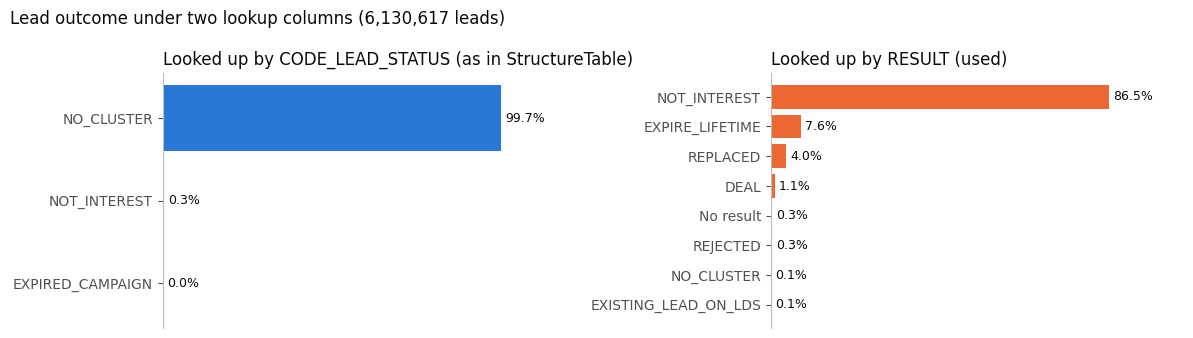

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for a, cach, ten, mau in [(ax[0], 'tra bằng code_lead_status', 'Looked up by CODE_LEAD_STATUS (as in StructureTable)', BLUE),
                          (ax[1], 'tra bằng result', 'Looked up by RESULT (used)', ORANGE)]:
    d = tra_lead[tra_lead.cach_tra == cach].copy()
    d['ket_qua'] = d.ket_qua.fillna('No result'); d['ty_trong'] = d.so_lead / d.so_lead.sum()
    d = d.sort_values('ty_trong')
    t = a.barh(d.ket_qua, d.ty_trong, color=mau); ghi_so(a, t, '{:.1%}')
    a.set_title(ten, loc='left', color=INK); bo_truc_x(a); a.margins(x=0.22)
tong = tra_lead[tra_lead.cach_tra == 'tra bằng result'].so_lead.sum()
fig.suptitle(f'Lead outcome under two lookup columns ({tong:,} leads)', x=0.01, ha='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_12_lead_lookup'); plt.show()


- Tra bằng `code_lead_status` như StructureTable ghi thì 6.110.204 trên 6.130.617 lead (6.110.204 + 20.311 + 102) là NO_CLUSTER, và không có lead nào là DEAL. Kết quả này không dùng được để biết lead có chốt được hay không.
- Tra bằng `result` thì kết quả hợp lý: 5.303.725 lead khách không quan tâm (NOT_INTEREST), 64.913 lead chốt được (DEAL), 20.411 lead chưa có kết quả.

Vì vậy notebook lấy kết quả lead từ cột `result` (cột `result_code` trong dữ liệu sạch là tên kết quả đã tra sẵn). Đây là điểm cần hỏi lại Ban tổ chức.

Câu lệnh dưới đây tạo bảng `lead_thang`: với mỗi shop trong bảng salesroom, trong mỗi tháng tạo lead (`created_month`) đến hết 09/2026, đếm số lead (`lead`) và số lead chốt được (`lead_chot`, tức `result` bằng 7, DEAL). Conversion rate (tỷ lệ chốt, cột `ty_le_chot`) = `lead_chot` / `lead`. Cuối ô là tổng theo tháng.

In [29]:
con.execute(f'''create or replace temp table lead_thang as
select skp_salesroom, created_month thang, count(*) lead, count(*) filter (where result=7) lead_chot
from leads where skp_salesroom in (select skp_salesroom from salesroom) and created_month<='{LAST_MONTH}'
group by all''')
lead_thang_t = q('''select thang, count(*) so_shop, sum(lead) lead, sum(lead_chot) lead_chot, sum(lead_chot)/sum(lead) ty_le_chot
from lead_thang group by 1 order by 1''')
lead_thang_t

,thang,so_shop,lead,lead_chot,ty_le_chot
0,2025-12-01,443,788,16,0.020
1,2026-01-01,4021,"25,737","1,014",0.039
2,2026-02-01,3788,"26,235","1,057",0.040
3,2026-03-01,4395,"36,479","1,367",0.037
4,2026-04-01,4548,"30,768","1,304",0.042
5,2026-05-01,4739,"30,983","1,280",0.041
6,2026-06-01,5193,"33,797","1,329",0.039
7,2026-07-01,5928,"42,156","1,598",0.038
8,2026-08-01,6696,"57,699","2,230",0.039
9,2026-09-01,6905,"66,580","2,351",0.035


Biểu đồ dưới đây vẽ lại bảng trên: bên trái là số lead tạo mỗi tháng, bên phải là tỷ lệ chốt. Ảnh được lưu thành `Bước 1/hinh/b1_13_leads_month.png`.

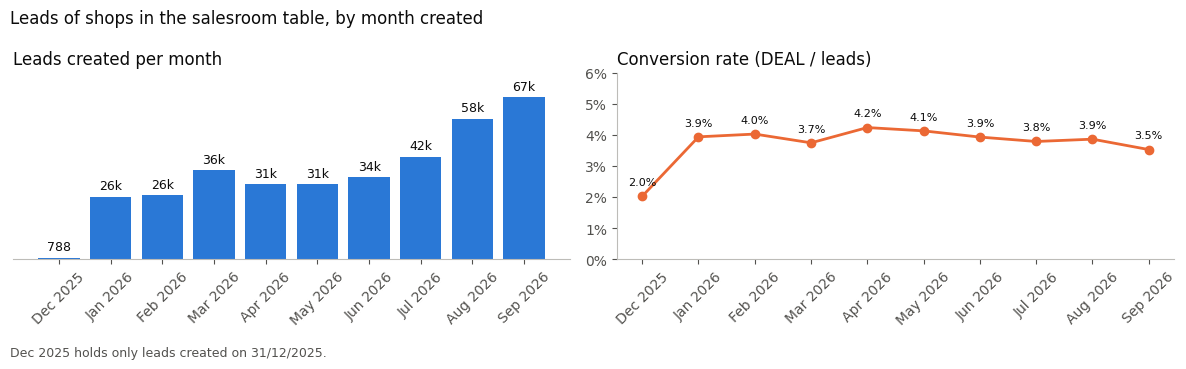

In [30]:
nhan = pd.to_datetime(lead_thang_t.thang).dt.strftime('%b %Y')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
t = ax[0].bar(nhan, lead_thang_t.lead, color=BLUE)
ax[0].bar_label(t, labels=[f'{v / 1000:.0f}k' if v >= 1000 else f'{v:,.0f}' for v in lead_thang_t.lead], padding=3, color=INK, fontsize=9)
ax[0].set_title('Leads created per month', loc='left', color=INK); bo_truc_y(ax[0]); ax[0].margins(y=0.15)
ax[1].plot(nhan, lead_thang_t.ty_le_chot, color=ORANGE, marker='o')
for xi, yi in zip(nhan, lead_thang_t.ty_le_chot):
    ax[1].annotate(f'{yi:.1%}', (xi, yi), textcoords='offset points', xytext=(0, 8), ha='center', color=INK, fontsize=8)
ax[1].set_ylim(0, 0.06); ax[1].yaxis.set_major_formatter(phan_tram())
ax[1].set_title('Conversion rate (DEAL / leads)', loc='left', color=INK)
for a in ax: a.tick_params(axis='x', rotation=45)
fig.suptitle('Leads of shops in the salesroom table, by month created', x=0.01, ha='left', color=INK)
fig.text(0.01, -0.04, 'Dec 2025 holds only leads created on 31/12/2025.', color=MUTED, fontsize=9)
plt.tight_layout(); luu_hinh(fig, 'b1_13_leads_month'); plt.show()


- Tỷ lệ chốt khoảng 3,5–4,2% mỗi tháng từ 01/2026 đến 09/2026, gần như không đổi.
- Tháng 12/2025 chỉ có 788 lead của 443 shop và tỷ lệ chốt 2,0%, vì dữ liệu lead của tháng này chỉ có ngày 31/12 (notebook EDA, Kiểm tra 1.2). Cần thận trọng khi dùng số của tháng 12/2025.

Câu lệnh dưới đây xem lead kết thúc thế nào: chia lead của các shop trong bảng theo kết quả (`result_code`) và theo sản phẩm được chào trong lead.

In [31]:
con.execute(f'''create or replace temp table lead_kq as
select skp_salesroom, coalesce(result_code, 'Không có kết quả') ket_qua, code_product_type san_pham, count(*) lead
from leads where skp_salesroom in (select skp_salesroom from salesroom) and created_month<='{LAST_MONTH}' group by all''')
lead_ket_qua = q('''select ket_qua, sum(lead) lead, sum(lead)/sum(sum(lead)) over () ty_trong,
  sum(lead) filter (where san_pham='CL') CL, sum(lead) filter (where san_pham='CC') CC,
  sum(lead) filter (where san_pham='CD') CD, sum(lead) filter (where san_pham='TW') TW, sum(lead) filter (where san_pham='REL') REL
from lead_kq group by 1 order by 2 desc''')
lead_ket_qua

,ket_qua,lead,ty_trong,CL,CC,CD,TW,REL
0,NOT_INTEREST,"266,729",0.759,"116,734","61,284","67,126","20,215","1,370"
1,EXPIRE_LIFETIME,"48,615",0.138,"8,810","10,751","22,297","5,748","1,009"
2,REPLACED,"18,001",0.051,"7,952","1,708","6,359","1,979",3
3,DEAL,"13,546",0.039,"4,246","9,245",NaN,43,12
4,REJECTED,"2,318",0.007,"1,137","1,156",NaN,15,10
5,Không có kết quả,"1,109",0.003,452,245,295,117,NaN
6,EXISTING_LEAD_ON_LDS,542,0.002,147,395,NaN,NaN,NaN
7,NO_CLUSTER,362,0.001,31,106,222,1,2


Biểu đồ dưới đây vẽ lại cột `ty_trong` của bảng trên: phần trăm lead theo kết quả, DEAL tô màu cam. Ảnh được lưu thành `Bước 1/hinh/b1_14_lead_outcome.png`.

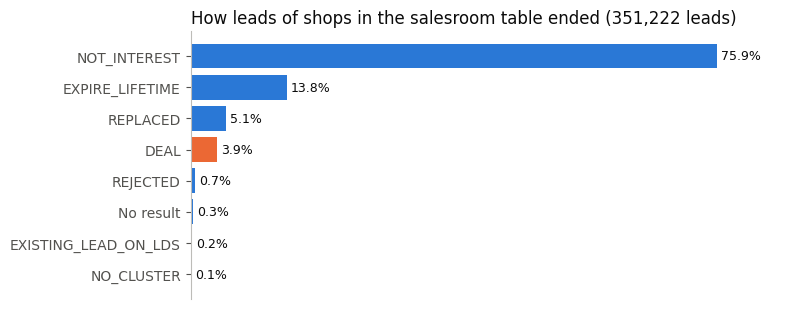

In [32]:
d = lead_ket_qua.copy(); d['ket_qua'] = d.ket_qua.replace({'Không có kết quả': 'No result'}); d = d.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.2))
t = ax.barh(d.ket_qua, d.ty_trong, color=[ORANGE if k == 'DEAL' else BLUE for k in d.ket_qua]); ghi_so(ax, t, '{:.1%}')
bo_truc_x(ax); ax.margins(x=0.12)
ax.set_title(f'How leads of shops in the salesroom table ended ({int(lead_ket_qua.lead.sum()):,} leads)', loc='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_14_lead_outcome'); plt.show()


Câu lệnh dưới đây tính tỷ lệ chốt theo sản phẩm của lead rồi vẽ lại.

,san_pham,lead,lead_chot,ty_le_chot
0,CC,84890,9245,0.109
1,CL,139509,4246,0.030
2,REL,2406,12,0.005
3,TW,28118,43,0.002
4,CD,96299,0,0


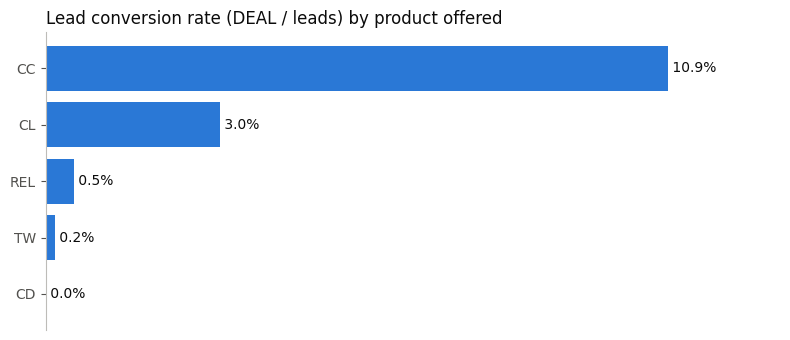

In [33]:
chot = q(f'''select code_product_type san_pham, count(*) lead, count(*) filter (where result=7) lead_chot, lead_chot / lead ty_le_chot
from leads where skp_salesroom in (select skp_salesroom from salesroom) and created_month<='{LAST_MONTH}'
group by 1 order by 4 desc''')
display(chot)
ve_cot_ngang(chot.san_pham.tolist(), chot.ty_le_chot.tolist(), 'Lead conversion rate (DEAL / leads) by product offered',
             '{:.1%}', ten='b1_15_lead_conversion_product')

- 75,9% lead kết thúc vì khách không quan tâm (NOT_INTEREST), 13,8% hết hạn (EXPIRE_LIFETIME), và chỉ 3,9% chốt được (DEAL).
- Tỷ lệ chốt khác hẳn giữa các sản phẩm: lead CC (thẻ tín dụng) chốt được 10,9% (9.245 trên 84.890 lead), lead CL (vay tiền mặt) chỉ 3,0% (4.246 trên 139.509), còn 96.299 lead CD không chốt được lead nào.

File `Bước 1/shop_lead_result.csv` lưu kết quả lead của từng shop.

Một lead chốt được chưa cho biết khách ký contract ở đâu. Mục tiếp theo nối lead với contract để trả lời câu hỏi này.

## 1.5. Cross-sell: contract ký ở nơi khác nhưng do lead của shop tạo ra

Một lead chốt được chưa cho biết contract được ký ở đâu. Nếu khách ký ngay tại shop thì contract đó đã nằm trong phần bán trực tiếp ở mục 1.3. Nếu khách ký ở shop khác hoặc qua kênh online, contract đó không được ghi tại shop, nhưng shop vẫn là nơi tạo ra cơ hội. Phần này tìm các contract đó.

Theo đề, một lead được nối với một contract khi đủ 3 điều kiện:
- cùng khách (`skp_client`);
- cùng sản phẩm: sản phẩm của lead (`code_product_type`) trùng sản phẩm của contract (`product`). Chỉ có bốn sản phẩm có cả lead và contract: CL, CC, TW, CD. Lead REL không có sản phẩm contract tương ứng nên không nối;
- lead được giao cho nhân viên (`date_assigned`) trước hoặc cùng lúc khách nộp hồ sơ (`date_apply`).

Nhóm thêm hai quy tắc, vì một contract thường nối được với nhiều lead của cùng một khách:
- mỗi contract chỉ ghi công cho **lead được giao gần nhất trước ngày nộp hồ sơ**. Lead gần nhất được chọn trong mọi lead của khách, kể cả lead của điểm bán ngoài bảng salesroom, rồi mới xét lead đó thuộc shop nào. Nếu chỉ chọn trong lead của các shop trong bảng, một contract mà lead gần nhất thuộc điểm bán ngoài bảng sẽ bị ghi công cho một lead cũ hơn của shop trong bảng. Nếu có từ 2 lead được giao đúng cùng thời điểm gần nhất, chọn lead có mã `id_uuid` đứng trước theo thứ tự chữ cái; cách chọn này chỉ để lần chạy nào cũng ra cùng một kết quả;
- lead phải được giao trong vòng `WINDOW_DAYS` = 30 ngày trước ngày nộp hồ sơ. Notebook EDA (mục 9.9) cho thấy giới hạn 30 ngày vẫn giữ khoảng 92% số lead DEAL nối được với contract, nhưng bỏ khoảng 41% số lead mà khách đã trả lời không quan tâm. Tức là giới hạn này chủ yếu bỏ đi các lần nối do trùng hợp. Cuối mục này kiểm tra kết quả thay đổi thế nào nếu dùng 90 ngày hoặc không giới hạn.

Không dùng cột `skp_credit_case` có sẵn trong bảng leads, vì khoảng 2/3 cặp lead vay tiền mặt – hồ sơ gắn sẵn có hồ sơ nộp trước khi lead được giao (notebook EDA, Kiểm tra 7.6), trái với điều kiện thứ 3 của đề.

Câu lệnh dưới đây nối lead với contract và đếm số cặp ở từng bước: mọi cặp thỏa 3 điều kiện của đề, sau khi giữ một lead mỗi contract, và sau khi áp giới hạn ngày.

In [34]:
con.execute('''create or replace temp table cap as
with l as (select row_number() over (order by id_uuid, date_assigned, skp_salesroom, code_product_type_original, id_lead_source) lead_id, id_uuid, skp_salesroom shop_lead, skp_client, code_product_type sp,
             date_assigned, result, result_code, id_lead_source
           from leads where code_product_type in ('CL','CC','TW','CD')),
k as (select skp_credit_case, skp_salesroom shop_hd, skp_client, product sp, date_apply, apply_month, is_signed
      from contract where product in ('CL','CC','TW','CD'))
select l.*, k.skp_credit_case, k.shop_hd, k.date_apply, k.apply_month, k.is_signed,
  date_diff('day', l.date_assigned, k.date_apply) so_ngay,
  row_number() over (partition by k.skp_credit_case order by l.date_assigned desc, l.lead_id) thu_tu,
  count(*) over (partition by k.skp_credit_case, l.date_assigned) so_lead_cung_thoi_diem
from l join k on l.skp_client=k.skp_client and l.sp=k.sp and k.date_apply>=l.date_assigned''')
ghep_buoc = q(f'''select 'Mọi cặp thỏa 3 điều kiện' buoc, count(*) so_cap, count(distinct skp_credit_case) so_hd from cap
union all select 'Giữ lead gần nhất', count(*), count(distinct skp_credit_case) from cap where thu_tu=1
union all select 'Giữ lead gần nhất, trong {WINDOW_DAYS} ngày', count(*), count(distinct skp_credit_case) from cap where thu_tu=1 and so_ngay<={WINDOW_DAYS}
union all select 'Trong đó: có từ 2 lead giao cùng thời điểm gần nhất', count(*), count(distinct skp_credit_case) from cap
  where thu_tu=1 and so_ngay<={WINDOW_DAYS} and so_lead_cung_thoi_diem>1''')
ghep_buoc

,buoc,so_cap,so_hd
0,Mọi cặp thỏa 3 điều kiện,339527,260674
1,Giữ lead gần nhất,260674,260674
2,"Giữ lead gần nhất, trong 30 ngày",179793,179793
3,Trong đó: có từ 2 lead giao cùng thời điểm gần...,731,731


Biểu đồ dưới đây vẽ lại ba dòng đầu của bảng trên: số dòng còn lại sau mỗi bước ghép lead với hồ sơ. Ảnh được lưu thành `Bước 1/hinh/b1_16_matching_steps.png`.

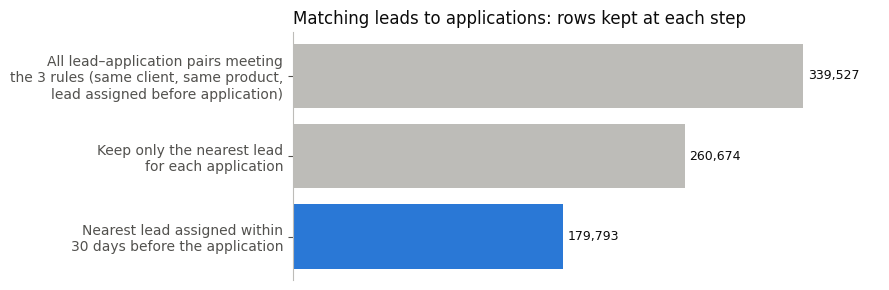

In [35]:
nhan = ['All lead–application pairs meeting\nthe 3 rules (same client, same product,\nlead assigned before application)',
        'Keep only the nearest lead\nfor each application', 'Nearest lead assigned within\n30 days before the application']
d = ghep_buoc.iloc[:3]
fig, ax = plt.subplots(figsize=(9, 3))
t = ax.barh(nhan[::-1], d.so_cap[::-1], color=[BLUE, '#bdbcb8', '#bdbcb8']); ghi_so(ax, t, '{:,.0f}')
bo_truc_x(ax); ax.margins(x=0.15)
ax.set_title('Matching leads to applications: rows kept at each step', loc='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_16_matching_steps'); plt.show()


- Nhiều hồ sơ nối được với hơn một lead (339.527 cặp trên 260.674 hồ sơ), nên cần quy tắc giữ một lead mỗi hồ sơ. Sau giới hạn 30 ngày, còn 179.793 hồ sơ được ghi công cho lead.
- 731 hồ sơ có từ 2 lead được giao đúng cùng thời điểm gần nhất. Với các hồ sơ này, lead được chọn theo mã `id_uuid` như quy tắc ở trên.

Câu lệnh dưới đây giữ kết quả cuối thành bảng `ghi_cong` (một lead mỗi contract, trong giới hạn ngày), rồi kiểm tra hai điều: mỗi contract chỉ xuất hiện một lần, và khoảng cách từ lúc giao lead đến lúc nộp hồ sơ nằm trong 0 đến 30 ngày.

In [36]:
con.execute(f'''create or replace temp table ghi_cong as
select * exclude (thu_tu, so_lead_cung_thoi_diem) from cap where thu_tu=1 and so_ngay<={WINDOW_DAYS}''')
q('''select count(*) so_dong, count(distinct skp_credit_case) so_hd_khac_nhau, min(so_ngay) so_ngay_nho_nhat, max(so_ngay) so_ngay_lon_nhat
from ghi_cong''')

,so_dong,so_hd_khac_nhau,so_ngay_nho_nhat,so_ngay_lon_nhat
0,179793,179793,0,30


Mỗi contract chỉ xuất hiện một lần (179.793 dòng, 179.793 contract khác nhau), và khoảng cách từ lúc giao lead đến lúc nộp hồ sơ nằm trong 0 đến 30 ngày, đúng như quy tắc.

Câu lệnh dưới đây lấy một ví dụ thật: một contract đã ký được ghi công cho lead của một shop trong bảng, nhưng ký ở điểm bán khác. Ví dụ được chọn là contract có mã nhỏ nhất thỏa điều kiện này.

In [37]:
q('''select shop_lead shop_tao_lead, sp san_pham, date_assigned ngay_giao_lead, result_code ket_qua_lead,
  skp_credit_case, shop_hd noi_ky_hd, (shop_hd in (select skp_salesroom from salesroom)) noi_ky_co_trong_bang,
  date_apply ngay_nop_ho_so, so_ngay
from ghi_cong where is_signed=1 and shop_lead in (select skp_salesroom from salesroom) and shop_hd is distinct from shop_lead
order by skp_credit_case limit 1''')

,shop_tao_lead,san_pham,ngay_giao_lead,ket_qua_lead,skp_credit_case,noi_ky_hd,noi_ky_co_trong_bang,ngay_nop_ho_so,so_ngay
0,115301670,CC,2025-12-31 09:25:07,DEAL,353316302,42902170,False,2025-12-31 09:33:42,0


Đọc dòng trên: lead CC (thẻ tín dụng) của shop 115301670 được giao lúc 09:25 ngày 31/12/2025 và có kết quả DEAL. Khoảng 8 phút sau, lúc 09:33 cùng ngày, khách nộp hồ sơ thẻ tín dụng, và contract 353316302 được ghi ở điểm bán 42902170, không có trong bảng salesroom (cột `noi_ky_co_trong_bang` bằng False). Nếu chỉ nhìn bảng contract, shop 115301670 không có contract này. Nhờ nối với lead, contract được ghi công là cross-sell của shop 115301670.

Câu lệnh dưới đây chia các contract đã ký trong bảng `ghi_cong` theo nơi ký so với shop tạo lead:
- lead của shop trong bảng, contract ký ở nơi khác: đây là phần cross-sell của shop;
- lead của shop trong bảng, contract ký ngay tại shop đó: phần này đã nằm trong bán trực tiếp ở mục 1.3, nên không tính lại;
- lead của điểm bán không có trong bảng salesroom: không ghi công được cho shop nào.

,nhom,hd_da_ky,ty_trong
0,"1. Lead của shop, ký ở nơi khác (cross-sell)",9609,0.071
1,"2. Lead của shop, ký tại chính shop đó",47340,0.349
2,3. Lead của điểm bán ngoài bảng,78610,0.580


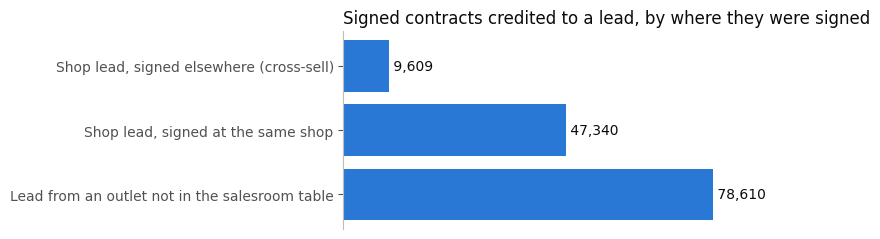

In [38]:
nhom_ghi_cong = q('''with g as (select *, case
      when shop_lead is null or shop_lead not in (select skp_salesroom from salesroom) then '3. Lead của điểm bán ngoài bảng'
      when shop_hd = shop_lead then '2. Lead của shop, ký tại chính shop đó'
      else '1. Lead của shop, ký ở nơi khác (cross-sell)' end nhom
    from ghi_cong where is_signed=1)
select nhom, count(*) hd_da_ky, count(*)/sum(count(*)) over () ty_trong
from g group by 1 order by 1''')
display(nhom_ghi_cong)
ten_nhom = {'1. Lead của shop, ký ở nơi khác (cross-sell)': 'Shop lead, signed elsewhere (cross-sell)',
            '2. Lead của shop, ký tại chính shop đó': 'Shop lead, signed at the same shop',
            '3. Lead của điểm bán ngoài bảng': 'Lead from an outlet not in the salesroom table'}
ve_cot_ngang([ten_nhom[k] for k in nhom_ghi_cong.nhom], nhom_ghi_cong.hd_da_ky.tolist(),
             'Signed contracts credited to a lead, by where they were signed', '{:,.0f}', ten='b1_17_signed_by_location')

- Trong 135.559 contract đã ký được ghi công cho lead (9.609 + 47.340 + 78.610), chỉ 9.609 contract (7,1%) là cross-sell của shop trong bảng (nhóm 1).
- 47.340 contract (34,9%) ký ngay tại shop tạo lead (nhóm 2). Các contract này đã được đếm trong bán trực tiếp ở mục 1.3, nên không cộng thêm để tránh đếm hai lần.
- 78.610 contract (58,0%) đến từ lead của điểm bán ngoài bảng salesroom (nhóm 3), nên không ghi công được cho shop nào.

Câu lệnh dưới đây tạo bảng `xsell`: phần cross-sell của từng shop theo tháng nộp hồ sơ (`xsell_hd`, số contract), rồi xem cross-sell theo sản phẩm.

In [39]:
con.execute('''create or replace temp table xsell as
select shop_lead skp_salesroom, apply_month thang, count(*) xsell_hd
from ghi_cong where is_signed=1 and shop_hd is distinct from shop_lead and shop_lead in (select skp_salesroom from salesroom)
group by all''')
xsell_sp = q('''with g as (select * from ghi_cong where is_signed=1 and shop_hd is distinct from shop_lead
             and shop_lead in (select skp_salesroom from salesroom))
select sp san_pham, count(*) xsell_hd, count(*) / (select count(*) from g) ty_trong, count(distinct shop_lead) so_shop
from g group by 1
union all select 'Tổng', count(*), 1, count(distinct shop_lead) from g
order by 2 desc''')
xsell_sp

,san_pham,xsell_hd,ty_trong,so_shop
0,Tổng,9609,1,3444
1,CC,6719,0.699,2618
2,CL,1596,0.166,1095
3,TW,969,0.101,325
4,CD,325,0.034,252


Biểu đồ dưới đây vẽ lại bảng trên: số contract cross-sell và tỷ trọng của từng sản phẩm. Ảnh được lưu thành `Bước 1/hinh/b1_18_xsell_product.png`.

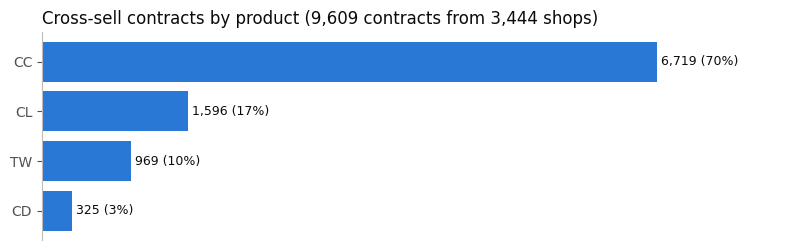

In [40]:
d = xsell_sp[xsell_sp.san_pham != 'Tổng'].iloc[::-1]
tong = xsell_sp[xsell_sp.san_pham == 'Tổng'].iloc[0]
fig, ax = plt.subplots(figsize=(8, 2.6))
t = ax.barh(d.san_pham, d.xsell_hd, color=BLUE)
ax.bar_label(t, labels=[f'{v:,} ({s:.0%})' for v, s in zip(d.xsell_hd, d.ty_trong)], padding=3, color=INK, fontsize=9)
bo_truc_x(ax); ax.margins(x=0.2)
ax.set_title(f'Cross-sell contracts by product ({tong.xsell_hd:,} contracts from {tong.so_shop:,} shops)', loc='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_18_xsell_product'); plt.show()


Cross-sell của shop chủ yếu là thẻ tín dụng CC: 6.719 trên 9.609 contract, tức 70%. Điều này khớp với mục 1.4: lead CC chốt được nhiều hơn hẳn lead CL.

**Kiểm tra độ nhạy của giới hạn ngày.** Câu lệnh dưới đây tính lại cross-sell của các shop trong bảng trong quý 3/2026 (trung bình mỗi tháng) với ba mức: 30 ngày, 90 ngày và không giới hạn. Cột cuối so cross-sell với tổng contract bán trực tiếp cộng cross-sell của cùng quý, để thấy giới hạn ngày làm tổng doanh số của shop thay đổi bao nhiêu.

In [41]:
cua_so = q(f'''with g as (select * from cap where thu_tu=1 and is_signed=1 and shop_hd is distinct from shop_lead
             and shop_lead in (select skp_salesroom from salesroom) and apply_month between '{CA_FROM}' and '{CA_TO}'),
tt as (select sum(hd_ky)/3 hd from truc_tiep where thang between '{CA_FROM}' and '{CA_TO}'),
m as (select 'Trong 30 ngày' muc, 1 thu_tu, count(*) filter (where so_ngay<=30)/3 xsell_moi_thang from g
  union all select 'Trong 90 ngày', 2, count(*) filter (where so_ngay<=90)/3 from g
  union all select 'Không giới hạn', 3, count(*)/3 from g)
select muc, xsell_moi_thang, xsell_moi_thang / first_value(xsell_moi_thang) over (order by thu_tu) so_voi_30_ngay,
  xsell_moi_thang / (xsell_moi_thang + tt.hd) ty_trong_trong_tong
from m, tt order by thu_tu''')
cua_so

,muc,xsell_moi_thang,so_voi_30_ngay,ty_trong_trong_tong
0,Trong 30 ngày,"1,827.7",1,0.045
1,Trong 90 ngày,"2,092.3",1.145,0.051
2,Không giới hạn,"2,482",1.358,0.060


Biểu đồ dưới đây vẽ lại bảng trên: số contract cross-sell mỗi tháng theo từng giới hạn ngày, kèm tỷ trọng trong tổng contract của shop. Ảnh được lưu thành `Bước 1/hinh/b1_19_xsell_window.png`.

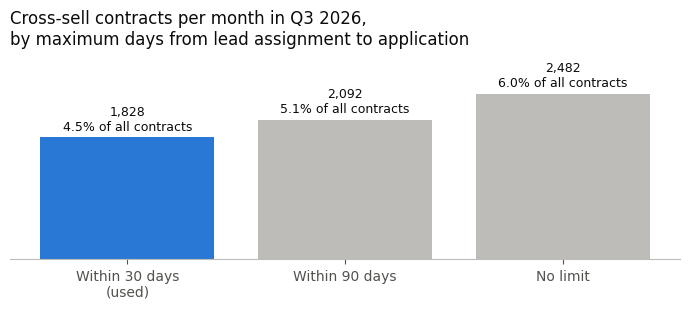

In [42]:
fig, ax = plt.subplots(figsize=(7, 3.2))
t = ax.bar(['Within 30 days\n(used)', 'Within 90 days', 'No limit'], cua_so.xsell_moi_thang, color=[BLUE, '#bdbcb8', '#bdbcb8'])
ax.bar_label(t, labels=[f'{v:,.0f}\n{s:.1%} of all contracts' for v, s in zip(cua_so.xsell_moi_thang, cua_so.ty_trong_trong_tong)],
             padding=3, color=INK, fontsize=9)
bo_truc_y(ax); ax.margins(y=0.25)
ax.set_title('Cross-sell contracts per month in Q3 2026,\nby maximum days from lead assignment to application', loc='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_19_xsell_window'); plt.show()


- Trong quý 3/2026, cross-sell của các shop trong bảng là 1.828 contract mỗi tháng với giới hạn 30 ngày. Dùng 90 ngày thì tăng 14%, bỏ hẳn giới hạn thì tăng 36%. Với riêng phần cross-sell, mức thay đổi này là đáng kể.
- Nhưng cross-sell chỉ chiếm 4,5% tổng contract của shop (bán trực tiếp cộng cross-sell) với giới hạn 30 ngày, và tăng lên 5,1% với 90 ngày, 6,0% nếu bỏ giới hạn. Vì vậy chọn giới hạn nào thì tổng doanh số của shop cũng thay đổi ít.

## 1.6. Ghép thành bảng shop × tháng

Câu lệnh dưới đây ghép bán trực tiếp (mục 1.3), lead (mục 1.4) và cross-sell (mục 1.5) thành một bảng `shop_month`:
- mỗi shop có đủ các tháng từ `thang_bat_dau` đến 09/2026. Tháng nào shop không có hồ sơ hay lead thì các cột đếm bằng 0. Một tháng không bán được gì cũng là một điểm dữ liệu khi xem xu hướng của shop. Bảng bắt đầu từ tháng shop bắt đầu hoạt động chứ không từ 01/2025, để một shop mở tháng 03/2026 không có 14 tháng bằng 0 trước khi mở;
- thêm các cột tỷ lệ: `ty_le_ky` (= `hd_ky` / `ho_so`), `ty_le_tu_choi` (= `hs_tu_choi` / `ho_so`), `ty_le_huy` (= `hs_huy` / `ho_so`), `ticket_trieu` (số tiền vay trung bình mỗi contract trả góp, triệu đồng), `ty_le_bao_hiem`, `ho_so_moi_sa`, `hd_moi_sa`, `ty_le_chot`;
- `hd_tong` = `hd_ky` + `xsell_hd`: tổng contract shop tạo ra, gồm bán trực tiếp và cross-sell.

Sau đó kiểm tra tổng `hd_ky` và `xsell_hd` của bảng mới phải bằng tổng ở mục 1.3 và 1.5.

In [43]:
con.execute(f'''create or replace temp table shop_month as
with g as (select s.skp_salesroom, unnest(generate_series(s.thang_bat_dau, date '{LAST_MONTH}', interval 1 month))::date thang
           from shop s where s.thang_bat_dau <= date '{LAST_MONTH}')
select g.skp_salesroom, g.thang,
  coalesce(t.ho_so,0) ho_so, coalesce(t.hd_ky,0) hd_ky, coalesce(t.hs_tu_choi,0) hs_tu_choi, coalesce(t.hs_huy,0) hs_huy, coalesce(t.so_tien,0) so_tien,
  coalesce(t.tien_vay_tra_gop,0) tien_vay_tra_gop, coalesce(t.hd_tra_gop,0) hd_tra_gop, coalesce(t.hd_bao_hiem,0) hd_bao_hiem,
  coalesce(t.hd_tinh_rui_ro,0) hd_tinh_rui_ro, coalesce(t.hd_tre_han,0) hd_tre_han, coalesce(t.so_sa,0) so_sa,
  coalesce(x.xsell_hd,0) xsell_hd,
  coalesce(l.lead,0) lead, coalesce(l.lead_chot,0) lead_chot,
  coalesce(t.hd_ky,0) + coalesce(x.xsell_hd,0) hd_tong,
  t.hd_ky / nullif(t.ho_so,0) ty_le_ky,
  t.hs_tu_choi / nullif(t.ho_so,0) ty_le_tu_choi,
  t.hs_huy / nullif(t.ho_so,0) ty_le_huy,
  t.tien_vay_tra_gop / nullif(t.hd_tra_gop,0) / 1e6 ticket_trieu,
  t.hd_bao_hiem / nullif(t.hd_tra_gop,0) ty_le_bao_hiem,
  t.ho_so / nullif(t.so_sa,0) ho_so_moi_sa,
  t.hd_ky / nullif(t.so_sa,0) hd_moi_sa,
  l.lead_chot / nullif(l.lead,0) ty_le_chot
from g left join truc_tiep t using(skp_salesroom, thang) left join xsell x using(skp_salesroom, thang)
left join lead_thang l using(skp_salesroom, thang)''')
q('''select count(*) so_dong, count(distinct skp_salesroom) so_shop, sum(hd_ky) hd_ky, (select sum(hd_ky) from truc_tiep) hd_ky_muc_1_3,
  sum(xsell_hd) xsell_hd, (select sum(xsell_hd) from xsell) xsell_hd_muc_1_5, sum((ho_so=0 and lead=0)::int) thang_khong_hoat_dong
from shop_month''')

,so_dong,so_shop,hd_ky,hd_ky_muc_1_3,xsell_hd,xsell_hd_muc_1_5,thang_khong_hoat_dong
0,148788,13937,"426,026","426,026","9,609","9,609","67,722"


Tổng `hd_ky` (426.026) và `xsell_hd` (9.609) của bảng mới đúng bằng tổng ở mục 1.3 và 1.5, nên việc ghép không làm mất hay nhân đôi dòng nào. Bảng có 148.788 dòng của 13.937 shop, trong đó 67.722 dòng là tháng shop không có hồ sơ hay lead nào.

## 1.7. Current Actual (mức hiện tại) của từng shop

Current Actual của một shop là số contract trung bình mỗi tháng trong 3 tháng 07, 08 và 09/2026:
- đây là 3 tháng gần nhất có đủ dữ liệu: hồ sơ cuối cùng trong bảng contract được nộp ngày 30/09/2026;
- lấy trung bình 3 tháng thay vì 1 tháng, vì một shop chỉ ký vài contract mỗi tháng nên số của từng tháng dao động nhiều.

Câu lệnh dưới đây tạo bảng `shop_current`, mỗi dòng một shop trong bảng salesroom (tháng không bán được thì tính là 0):
- `ca_hd_truc_tiep`: phần bán trực tiếp tại shop;
- `ca_xsell`: phần cross-sell;
- `ca_hd_tong`: tổng hai phần trên. Đây là Current Actual chính của shop;
- `ca_so_tien`: funded volume mỗi tháng;
- các KPI cùng kỳ: số hồ sơ, số SA, hồ sơ mỗi SA, tỷ lệ ký, tỷ lệ bị từ chối, tỷ lệ hủy, ticket size, tỷ lệ bảo hiểm, số lead, số lead chốt được, tỷ lệ chốt (`ca_ty_le_chot`), và số contract cross-sell trên mỗi lead (`ca_xsell_moi_lead`);
- `rr_hd` và `rr_ty_le_tre`: số contract tính rủi ro và tỷ lệ contract có khách trễ hạn ít nhất một trong 4 kỳ đầu, tính trên cả giai đoạn ký 03/2025 – 05/2026 để có đủ số contract.

Các tỷ lệ trong quý được tính bằng tổng của quý chia tổng của quý, không lấy trung bình các tỷ lệ từng tháng. Ví dụ một shop tháng 7 có 1 hồ sơ và ký được (tỷ lệ ký 100%), tháng 8 có 10 hồ sơ, ký được 5 (50%): trung bình hai tỷ lệ là 75%, nhưng tỷ lệ thật của shop là 6 / 11 ≈ 55%. Tính bằng tổng chia tổng thì công thức ở đầu notebook (số SA × hồ sơ mỗi SA × (1 − tỷ lệ bị từ chối − tỷ lệ hủy) = contract bán trực tiếp) luôn đúng.

Cuối ô in tổng của toàn bộ shop, và sai lệch lớn nhất giữa hai vế của công thức trên.

In [44]:
con.execute(f'''create or replace temp table shop_current as
with q3 as (select skp_salesroom, sum(hd_ky)/3 ca_hd_truc_tiep, sum(xsell_hd)/3 ca_xsell, sum(hd_tong)/3 ca_hd_tong,
    sum(so_tien)/3 ca_so_tien, sum(ho_so)/3 ca_ho_so, sum(so_sa)/3 ca_so_sa,
    sum(ho_so)/nullif(sum(so_sa),0) ca_ho_so_moi_sa, sum(hd_ky)/nullif(sum(ho_so),0) ca_ty_le_ky,
    sum(hs_tu_choi)/nullif(sum(ho_so),0) ca_ty_le_tu_choi, sum(hs_huy)/nullif(sum(ho_so),0) ca_ty_le_huy,
    sum(tien_vay_tra_gop)/nullif(sum(hd_tra_gop),0)/1e6 ca_ticket_trieu, sum(hd_bao_hiem)/nullif(sum(hd_tra_gop),0) ca_ty_le_bao_hiem,
    sum(lead)/3 ca_lead, sum(lead_chot)/3 ca_lead_chot, sum(lead_chot)/nullif(sum(lead),0) ca_ty_le_chot,
    sum(xsell_hd)/nullif(sum(lead),0) ca_xsell_moi_lead
  from shop_month where thang between '{CA_FROM}' and '{CA_TO}' group by 1),
rr as (select skp_salesroom, sum(hd_tinh_rui_ro) rr_hd, sum(hd_tre_han)/nullif(sum(hd_tinh_rui_ro),0) rr_ty_le_tre from shop_month group by 1)
select s.*, (s.salesroom_category='Virtual')::int shop_online,
  coalesce(q3.ca_hd_truc_tiep,0) ca_hd_truc_tiep, coalesce(q3.ca_xsell,0) ca_xsell, coalesce(q3.ca_hd_tong,0) ca_hd_tong,
  coalesce(q3.ca_so_tien,0) ca_so_tien, coalesce(q3.ca_ho_so,0) ca_ho_so, coalesce(q3.ca_so_sa,0) ca_so_sa,
  q3.ca_ho_so_moi_sa, q3.ca_ty_le_ky, q3.ca_ty_le_tu_choi, q3.ca_ty_le_huy, q3.ca_ticket_trieu, q3.ca_ty_le_bao_hiem,
  coalesce(q3.ca_lead,0) ca_lead, coalesce(q3.ca_lead_chot,0) ca_lead_chot, q3.ca_ty_le_chot, q3.ca_xsell_moi_lead,
  coalesce(rr.rr_hd,0) rr_hd, rr.rr_ty_le_tre
from shop s left join q3 using(skp_salesroom) left join rr using(skp_salesroom)''')
q('''select count(*) so_shop, sum(ca_hd_truc_tiep) tong_truc_tiep, sum(ca_xsell) tong_xsell, sum(ca_hd_tong) tong,
  sum(ca_xsell)/sum(ca_hd_tong) ty_trong_xsell,
  max(abs(ca_so_sa*ca_ho_so_moi_sa*(1-ca_ty_le_tu_choi-ca_ty_le_huy) - ca_hd_truc_tiep)) sai_lech_lon_nhat_cua_cong_thuc
from shop_current''')

,so_shop,tong_truc_tiep,tong_xsell,tong,ty_trong_xsell,sai_lech_lon_nhat_cua_cong_thuc
0,14216,"38,579.3","1,827.7","40,407.0",0.045,0.000


- Tổng Current Actual của mọi shop trong bảng salesroom là 40.407 contract mỗi tháng: 38.579 contract bán trực tiếp và 1.828 contract cross-sell. Cross-sell chỉ chiếm 4,5%.
- Cột cuối bằng 0: với mọi shop, số SA × hồ sơ mỗi SA × (1 − tỷ lệ bị từ chối − tỷ lệ hủy) ra đúng số contract bán trực tiếp. Công thức này đúng theo cách định nghĩa, nên dòng kiểm tra chỉ xác nhận việc tính không mất dòng hay lỗi chia; giá trị của nó là tách doanh số thành từng phần để so với shop cùng loại.

Câu lệnh dưới đây lấy một shop thật để đọc công thức: shop Active, không phải shop online, có trung bình đúng 2 SA mỗi tháng và có cross-sell trong quý. Trong các shop như vậy, lấy shop có Current Actual cao nhất.

In [45]:
q('''select skp_salesroom, salesroom_product nganh_hang, salesroom_category co_shop, salesroom_province tinh,
  ca_so_sa, ca_ho_so_moi_sa, ca_ty_le_tu_choi, ca_ty_le_huy, ca_ty_le_ky, ca_hd_truc_tiep, ca_xsell, ca_hd_tong
from shop_current where salesroom_status='Active' and shop_online=0 and ca_so_sa=2 and ca_xsell>0
order by ca_hd_tong desc, skp_salesroom limit 1''')

,skp_salesroom,nganh_hang,co_shop,tinh,ca_so_sa,ca_ho_so_moi_sa,ca_ty_le_tu_choi,ca_ty_le_huy,ca_ty_le_ky,ca_hd_truc_tiep,ca_xsell,ca_hd_tong
0,122941845,CD,Big,TP.HCM,2,35.667,0.178,0.056,0.766,54.667,10.333,65


Shop 122941845 (CD, cỡ Big, TP.HCM) có trung bình 2 SA mỗi tháng, mỗi SA làm 35,7 hồ sơ. 17,8% hồ sơ bị từ chối và 5,6% bị hủy, nên 76,6% hồ sơ thành contract: 2 × 35,667 × 0,766 ≈ 54,6, đúng bằng 54,667 contract bán trực tiếp mỗi tháng (lệch nhỏ vì tỷ lệ được in làm tròn). Cộng 10,333 contract cross-sell thì Current Actual của shop là 65 contract mỗi tháng.

Viết như vậy, Current Actual của mỗi shop được tách thành năm phần: số SA, số hồ sơ mỗi SA, tỷ lệ bị từ chối, tỷ lệ hủy và cross-sell. Khi so một shop với các shop cùng loại, có thể chỉ ra shop đang kém ở phần nào.

Câu lệnh dưới đây chia các shop Active, không tính shop online, theo Current Actual (`ca_hd_tong`) thành các khoảng: 0, trên 0 đến 1, trên 1 đến 3, trên 3 đến 5, trên 5 đến 10, và trên 10 contract mỗi tháng. Với mỗi khoảng, đếm số shop và tính phần trăm tổng Current Actual mà các shop này tạo ra.

,khoang,so_shop,ty_le_shop,ty_trong_hd
0,1. 0,3975,0.338,0
1,2. trên 0 đến 1,2716,0.231,0.040
2,3. trên 1 đến 3,2160,0.184,0.111
3,4. trên 3 đến 5,920,0.078,0.095
4,5. trên 5 đến 10,1027,0.087,0.189
5,6. trên 10,954,0.081,0.565


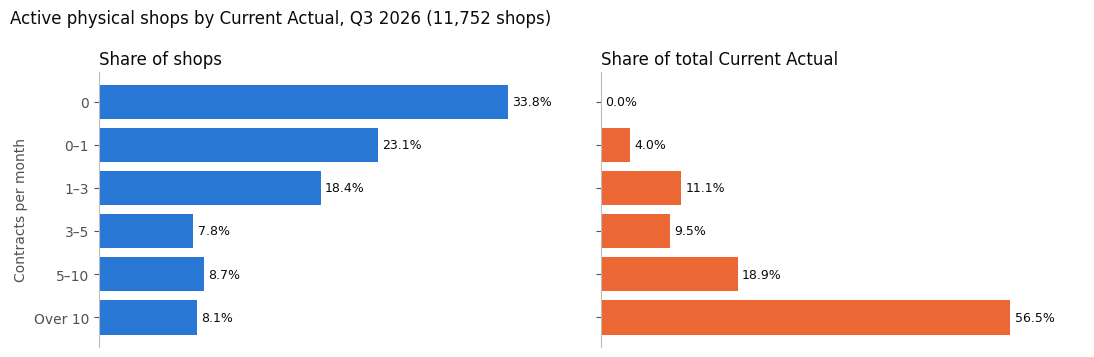

In [46]:
khoang = q('''with s as (select ca_hd_tong, case when ca_hd_tong=0 then '1. 0'
      when ca_hd_tong<=1 then '2. trên 0 đến 1' when ca_hd_tong<=3 then '3. trên 1 đến 3'
      when ca_hd_tong<=5 then '4. trên 3 đến 5' when ca_hd_tong<=10 then '5. trên 5 đến 10' else '6. trên 10' end khoang
    from shop_current where salesroom_status='Active' and shop_online=0)
select khoang, count(*) so_shop, count(*)/sum(count(*)) over () ty_le_shop, sum(ca_hd_tong)/sum(sum(ca_hd_tong)) over () ty_trong_hd
from s group by 1 order by 1''')
display(khoang)
ten_khoang = {'1. 0': '0', '2. trên 0 đến 1': '0–1', '3. trên 1 đến 3': '1–3', '4. trên 3 đến 5': '3–5',
              '5. trên 5 đến 10': '5–10', '6. trên 10': 'Over 10'}
nhan = [ten_khoang[k] for k in khoang.khoang][::-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
t = ax[0].barh(nhan, khoang.ty_le_shop[::-1], color=BLUE); ghi_so(ax[0], t, '{:.1%}')
ax[0].set_title('Share of shops', loc='left', color=INK)
t = ax[1].barh(nhan, khoang.ty_trong_hd[::-1], color=ORANGE); ghi_so(ax[1], t, '{:.1%}')
ax[1].set_title('Share of total Current Actual', loc='left', color=INK)
for a in ax: bo_truc_x(a); a.margins(x=0.18)
ax[0].set_ylabel('Contracts per month')
fig.suptitle(f'Active physical shops by Current Actual, Q3 2026 ({khoang.so_shop.sum():,} shops)', x=0.01, ha='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_20_ca_bands'); plt.show()


- 3.975 shop Active có mặt bằng, tức 33,8%, không ký được contract nào trong quý 3/2026. Thêm 2.716 shop (23,1%) ký không quá 1 contract mỗi tháng.
- Ngược lại, 954 shop (8,1%) ký trên 10 contract mỗi tháng và tạo ra 56,5% tổng Current Actual.

Như vậy doanh số dồn vào một nhóm nhỏ shop, còn hơn một nửa số shop (33,8% + 23,1% = 56,9%) gần như không bán được. Với nhóm shop bán ít này, câu hỏi tiếp theo là shop nào có thể bán nhiều hơn và vì sao.

Câu lệnh dưới đây xem Current Actual của các shop Active, không tính shop online, theo ngành hàng chính và cỡ shop: số shop, số shop không ký được contract nào trong quý, và mức 25%, trung vị, mức 75% của `ca_hd_tong`.

In [47]:
ca_nhom = q('''select salesroom_product nganh_hang, salesroom_category co_shop, count(*) so_shop, count(*) filter (where ca_hd_tong=0) shop_bang_0,
  shop_bang_0 / so_shop ty_le_shop_bang_0,
  quantile_cont(ca_hd_tong, 0.25) muc_25, median(ca_hd_tong) trung_vi, quantile_cont(ca_hd_tong, 0.75) muc_75,
  sum(shop_moi) shop_moi
from shop_current where salesroom_status='Active' and shop_online=0 group by all order by 1, 2''')
ca_nhom

,nganh_hang,co_shop,so_shop,shop_bang_0,ty_le_shop_bang_0,muc_25,trung_vi,muc_75,shop_moi
0,CD,Big,451,129,0.286,0,1,5.333,192
1,CD,Medium,1858,588,0.316,0,1,4,621
2,CD,Small,3848,1261,0.328,0,0.667,2.667,976
3,NS,Big,439,187,0.426,0,0.333,3,245
4,NS,Medium,1643,690,0.420,0,0.333,2.667,643
5,NS,Small,1226,445,0.363,0,0.667,2.667,373
6,TW,Big,390,99,0.254,0,1.667,6,180
7,TW,Medium,908,255,0.281,0,1,4,282
8,TW,Small,989,321,0.325,0,0.667,2.667,309


Biểu đồ dưới đây vẽ lại bảng trên: bên trái là phần trăm shop không ký được contract nào, bên phải là Current Actual của shop đứng giữa (chấm tròn) và khoảng từ mức 25% đến mức 75% (đoạn ngang). Ảnh được lưu thành `Bước 1/hinh/b1_21_ca_by_group.png`.

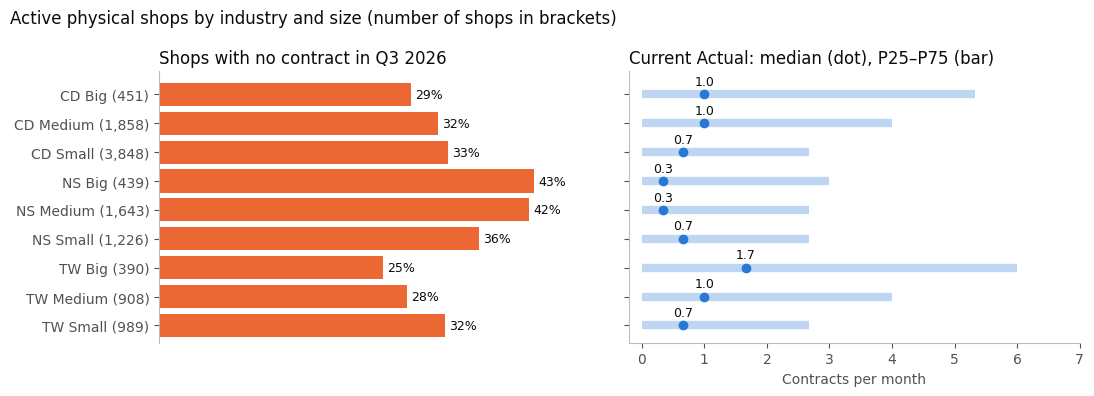

In [48]:
nhan = [f'{n} {c} ({s:,})' for n, c, s in zip(ca_nhom.nganh_hang, ca_nhom.co_shop, ca_nhom.so_shop)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
y = np.arange(len(nhan))[::-1]
t = ax[0].barh(y, ca_nhom.ty_le_shop_bang_0, color=ORANGE); ghi_so(ax[0], t, '{:.0%}')
ax[0].set_yticks(y); ax[0].set_yticklabels(nhan); bo_truc_x(ax[0]); ax[0].margins(x=0.2)
ax[0].set_title('Shops with no contract in Q3 2026', loc='left', color=INK)
ve_khoang(ax[1], nhan, ca_nhom.trung_vi, ca_nhom.muc_25, ca_nhom.muc_75, '{:.1f}')
ax[1].set_xlim(-0.2, 7); ax[1].set_xlabel('Contracts per month')
ax[1].set_title('Current Actual: median (dot), P25–P75 (bar)', loc='left', color=INK)
fig.suptitle('Active physical shops by industry and size (number of shops in brackets)', x=0.01, ha='left', color=INK)
plt.tight_layout(); luu_hinh(fig, 'b1_21_ca_by_group'); plt.show()


- Trong mỗi nhóm, từ 25% đến 43% số shop Active không ký được contract nào trong quý 3/2026 (cột `ty_le_shop_bang_0`).
- Shop đứng giữa mỗi nhóm chỉ ký 0,3–1,7 contract mỗi tháng. Con số này thấp hơn mức 2 contract ở Bước 0 (mục 0.2), vì Bước 0 chỉ tính các shop ký được contract, còn ở đây tính cả các shop không bán được.
- Ở mức trung vị, shop Big chỉ hơn shop Small một chút (shop CD: 1 so với 0,7 contract mỗi tháng). Khác biệt rõ hơn ở nhóm bán tốt: 1/4 shop CD Big tốt nhất ký từ 5,3 contract mỗi tháng, so với 2,7 ở shop CD Small.

## 1.8. Ghi kết quả

Ô dưới đây ghi các bảng vào thư mục `Bước 1/`.

In [49]:
def ghi(df, ten):
    # ghi vào thư mục Bước 1, mã UTF-8 có BOM để Excel đọc đúng tiếng Việt
    df.to_csv(ROOT / 'Bước 1' / f'{ten}.csv', index=False, encoding='utf-8-sig')
    print(f'Đã ghi Bước 1/{ten}.csv: {len(df):,} dòng')

ghi(q('select * from shop_month order by skp_salesroom, thang'), 'shop_month')
ghi(q('select * from shop_current order by skp_salesroom'), 'shop_current')
ghi(q('select * from mix order by skp_salesroom, hd_ky desc, nhom_hang'), 'shop_goods_mix')
ghi(q('select * from lead_kq order by skp_salesroom, lead desc, ket_qua, san_pham'), 'shop_lead_result')
ghi(q('''select id_uuid, lead_id, shop_lead, id_lead_source, sp san_pham, date_assigned, result,
  skp_credit_case, shop_hd, date_apply, apply_month, is_signed, so_ngay from ghi_cong order by skp_credit_case'''), 'lead_contract_match')

Đã ghi Bước 1/shop_month.csv: 148,788 dòng


Đã ghi Bước 1/shop_current.csv: 14,216 dòng
Đã ghi Bước 1/shop_goods_mix.csv: 11,811 dòng


Đã ghi Bước 1/shop_lead_result.csv: 45,988 dòng


Đã ghi Bước 1/lead_contract_match.csv: 179,793 dòng


## 1.9. Hai bảng đầu vào cho Bước 2

Bước 2 dự báo BAU từ hai bảng: KPI của từng shop theo từng tháng, và danh sách contract cross-sell được ghi công cho shop. Ô dưới đây tạo hai bảng này từ chính các bảng ở trên, đặt tên cột theo đúng tên mà notebook Bước 2 đọc:
- `shop_month_kpi.csv`: mỗi dòng là một shop trong một tháng, đủ 21 tháng (01/2025 – 09/2026) cho mọi shop Active có mặt bằng, kể cả shop bắt đầu hoạt động sau 09/2026 (các tháng đều bằng 0). Các shop online đang Active được gộp thành một dòng `VIRTUAL` mỗi tháng. `first_seen_month` là tháng đầu tiên shop có hồ sơ hoặc contract; `shop_age_group` là "shop mới" nếu tháng đó cách 09/2026 dưới 6 tháng. Các cột cross-sell đếm mọi contract đã ký được ghi công cho lead của shop theo cách nối ở mục 1.5, gồm cả contract ký ngay tại shop tạo lead (`cross_sell_booked_same_shop`) và ký ở nơi khác (`cross_sell_booked_elsewhere_or_online`, chính là cột `xsell_hd` ở trên).
- `cross_sell_attribution.csv`: mỗi dòng là một contract cross-sell đã ký, gồm shop được ghi công, nơi ký, tháng ký và số tiền cho vay.

Dòng kiểm tra cuối so tổng của bảng mới với các bảng ở trên.

In [50]:
import numpy as np
tien = """case when k.product in ('CC','BNPL') then coalesce(k.amt_billing_1st,0)+coalesce(k.amt_billing_2nd,0)+coalesce(k.amt_billing_3rd,0)
            else k.credit_amount end"""
xa = q(f"""select g.skp_credit_case, g.shop_lead credited_shop_id, g.shop_hd contract_skp_salesroom, g.shop_lead lead_skp_salesroom,
  g.apply_month, k.sign_month, {tien} funded_amount
from ghi_cong g join contract k using(skp_credit_case)
where g.is_signed=1 and g.shop_lead in (select skp_salesroom from salesroom)""")
xa['cung_shop'] = xa.contract_skp_salesroom == xa.lead_skp_salesroom
xs = xa.groupby(['credited_shop_id', 'apply_month']).agg(
    cross_sell_contracts=('skp_credit_case', 'size'), cross_sell_funded_volume=('funded_amount', 'sum'),
    cross_sell_booked_same_shop=('cung_shop', 'sum')).reset_index()
xs['cross_sell_booked_elsewhere_or_online'] = xs.cross_sell_contracts - xs.cross_sell_booked_same_shop
xs = xs.rename(columns={'credited_shop_id': 'skp_salesroom', 'apply_month': 'thang'})

sm_ = q('select * from shop_month')
sh = q("""select skp_salesroom, salesroom_category, salesroom_model, salesroom_province, salesroom_area
          from salesroom where salesroom_status='Active'""")
sm_ = sm_.merge(xs, on=['skp_salesroom', 'thang'], how='left')
dem = ['ho_so', 'hd_ky', 'so_tien', 'hd_tra_gop', 'hd_bao_hiem', 'so_sa', 'hd_tinh_rui_ro', 'hd_tre_han', 'lead', 'lead_chot',
       'cross_sell_contracts', 'cross_sell_funded_volume', 'cross_sell_booked_same_shop', 'cross_sell_booked_elsewhere_or_online']
sm_[dem] = sm_[dem].fillna(0)
sm_ = sm_.merge(sh, on='skp_salesroom')
sm_['shop_id'] = np.where(sm_.salesroom_category == 'Virtual', 'VIRTUAL', sm_.skp_salesroom.astype(str))
for c in ['salesroom_model', 'salesroom_province', 'salesroom_area']:
    sm_.loc[sm_.shop_id == 'VIRTUAL', c] = 'VIRTUAL'
g = sm_.groupby(['shop_id', 'thang'])[dem].sum().reset_index()
sh['shop_id'] = np.where(sh.salesroom_category == 'Virtual', 'VIRTUAL', sh.skp_salesroom.astype(str))
for c in ['salesroom_model', 'salesroom_province', 'salesroom_area']:
    sh.loc[sh.shop_id == 'VIRTUAL', c] = 'VIRTUAL'
thong_tin = sh.drop_duplicates('shop_id').set_index('shop_id')[['salesroom_category', 'salesroom_model', 'salesroom_province', 'salesroom_area']]   # mọi shop Active, kể cả shop chưa đến tháng bắt đầu
luoi = pd.MultiIndex.from_product([thong_tin.index, pd.date_range('2025-01-01', LAST_MONTH, freq='MS')], names=['shop_id', 'thang']).to_frame(index=False)
g['thang'] = pd.to_datetime(g.thang)
k = luoi.merge(g, on=['shop_id', 'thang'], how='left').fillna({c: 0 for c in dem}).join(thong_tin, on='shop_id')
dau = k[(k.ho_so > 0) | (k.hd_ky > 0)].groupby('shop_id').thang.min().rename('first_seen_month')
k = k.join(dau, on='shop_id')
tuoi = (pd.Timestamp(LAST_MONTH).year - k.first_seen_month.dt.year) * 12 + pd.Timestamp(LAST_MONTH).month - k.first_seen_month.dt.month
k['shop_age_group'] = np.select([k.first_seen_month.isna(), tuoi < 6], ['chưa phát sinh', 'shop mới'], 'shop hiện hữu')
chia = lambda a, b: a / b.where(b > 0)
kpi = pd.DataFrame({
    'shop_id': k.shop_id, 'shop_category': k.salesroom_category, 'salesroom_model': k.salesroom_model,
    'salesroom_province': k.salesroom_province, 'salesroom_area': k.salesroom_area, 'month': k.thang,
    'applications': k.ho_so, 'approved_from_apply_cohort': k.hd_ky, 'approval_rate': chia(k.hd_ky, k.ho_so),
    'signed_contracts': k.hd_ky, 'funded_volume': k.so_tien, 'avg_ticket_size': chia(k.so_tien, k.hd_ky),
    'insurance_rate': chia(k.hd_bao_hiem, k.hd_tra_gop), 'headcount_sa': k.so_sa, 'productivity': chia(k.hd_ky, k.so_sa),
    'risk_eligible_contracts': k.hd_tinh_rui_ro, 'first_payment_default_contracts': k.hd_tre_han, 'risk_rate': chia(k.hd_tre_han, k.hd_tinh_rui_ro),
    'first_seen_month': k.first_seen_month, 'shop_age_group': k.shop_age_group,
    'leads_created': k.lead, 'leads_deal': k.lead_chot, 'conversion_rate': chia(k.lead_chot, k.lead),
    'cross_sell_contracts': k.cross_sell_contracts, 'cross_sell_funded_volume': k.cross_sell_funded_volume,
    'cross_sell_avg_ticket_size': chia(k.cross_sell_funded_volume, k.cross_sell_contracts),
    'cross_sell_booked_same_shop': k.cross_sell_booked_same_shop,
    'cross_sell_booked_elsewhere_or_online': k.cross_sell_booked_elsewhere_or_online})
kpi.to_csv(ROOT / 'Bước 1' / 'shop_month_kpi.csv', index=False, encoding='utf-8-sig')
xa.drop(columns='cung_shop').to_csv(ROOT / 'Bước 1' / 'cross_sell_attribution.csv', index=False, encoding='utf-8-sig')
print(f"Đã ghi Bước 1/shop_month_kpi.csv: {len(kpi):,} dòng, {kpi.shop_id.nunique():,} shop (gồm dòng VIRTUAL) × {kpi.month.nunique()} tháng")
print(f"Đã ghi Bước 1/cross_sell_attribution.csv: {len(xa):,} contract cross-sell đã ký")
q3_ = kpi[(kpi.month >= CA_FROM) & (kpi.shop_id != 'VIRTUAL')]
cur_ = q("select * from shop_current where salesroom_status='Active' and shop_online=0")
print(f"Kiểm tra quý 3/2026, shop Active có mặt bằng: bán trực tiếp {q3_.signed_contracts.sum() / 3:,.1f} (mục 1.7: {cur_.ca_hd_truc_tiep.sum():,.1f}); "
      f"cross-sell ký nơi khác {q3_.cross_sell_booked_elsewhere_or_online.sum() / 3:,.1f} (mục 1.7: {cur_.ca_xsell.sum():,.1f}); "
      f"cross-sell gồm cả ký tại shop {q3_.cross_sell_contracts.sum() / 3:,.1f} contract mỗi tháng")

Đã ghi Bước 1/shop_month_kpi.csv: 246,813 dòng, 11,753 shop (gồm dòng VIRTUAL) × 21 tháng
Đã ghi Bước 1/cross_sell_attribution.csv: 56,949 contract cross-sell đã ký
Kiểm tra quý 3/2026, shop Active có mặt bằng: bán trực tiếp 37,664.0 (mục 1.7: 37,664.0); cross-sell ký nơi khác 1,786.0 (mục 1.7: 1,786.0); cross-sell gồm cả ký tại shop 8,573.3 contract mỗi tháng


## 1.10. Tóm tắt

- **Shop bán rất ít, và doanh số dồn vào một nhóm nhỏ.** 33,8% shop Active có mặt bằng không ký được contract nào trong quý 3/2026, trong khi 8,1% shop ký trên 10 contract mỗi tháng tạo ra 56,5% tổng Current Actual.
- **Doanh số của shop gần như toàn bộ là bán trực tiếp.** Cross-sell chỉ chiếm 4,5% Current Actual, chủ yếu là thẻ tín dụng. Phần bán trực tiếp tách thành số SA × hồ sơ mỗi SA × (1 − tỷ lệ bị từ chối − tỷ lệ hủy).
- **Mỗi phần của công thức khác nhau nhiều giữa các shop.** 2/3 số shop-tháng chỉ có 1 SA. Với shop CD Non-Aldi, 1/4 số shop có tỷ lệ bị từ chối dưới 10,7% trong khi 1/4 số shop trên 30%; tỷ lệ hủy dưới 1,4% ở 1/4 số shop tốt nhất và trên 10,5% ở 1/4 số shop kém nhất.
- **Tỷ lệ ký tăng từ 57–64% lên 71–72%** từ nửa đầu năm 2025 đến quý 3/2026, hoàn toàn nhờ ít hồ sơ bị từ chối hơn; tỷ lệ hủy không giảm.
- **Rủi ro cũng khác nhau rõ.** Trong các shop có đủ 30 contract, tỷ lệ contract có khách trễ hạn trong 4 kỳ đầu từ dưới 16,7% (1/10 số shop tốt nhất) đến trên 44,9% (1/10 số shop kém nhất). Shop NS có tỷ lệ trễ cao nhất (34,1%).
- **Bảo hiểm khác hẳn theo kiểu làm hồ sơ.** 87,2% contract có bảo hiểm ở shop CD Non-Aldi, nhưng chỉ 0,2% ở shop CD Aldi.
- **Lead CC chốt tốt hơn lead CL nhiều lần:** 10,9% so với 3,0%; tính chung chỉ 3,9% lead chốt được. Kết quả lead lấy từ cột `result`, vì tra theo `code_lead_status` như StructureTable ghi thì gần như mọi lead là NO_CLUSTER; cần Ban tổ chức xác nhận.
- Doanh số chính được đo bằng số contract (`ca_hd_tong`), vì số tiền mỗi contract khác nhau rất nhiều giữa các sản phẩm. Kết quả nằm trong `output/shop_month.csv` (mỗi shop mỗi tháng) và `output/shop_current.csv` (Current Actual của mỗi shop).